<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/HybridQNN_PowerTheft_Blazakis2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum neural network (FH-QVC-DRC) for electricity-theft detection: Blazakis et al. 2025, step by step

**Paper.** K. Blazakis, N. Schetakis, M. M. Badr, D. Aghamalyan, K. Stavrakakis, G. Stavrakakis,
*"Power Theft Detection in Smart Grids Using Quantum Machine Learning"*, **IEEE Access 13**, 61511-61523, 2025.
DOI: [10.1109/ACCESS.2025.3558143](https://doi.org/10.1109/ACCESS.2025.3558143).

**What this notebook does.** Electricity theft means that a customer (or the owner of a rooftop solar system)
sends *falsified readings* from the smart meter to the utility. The paper proposes a "full hybrid"
quantum neural network, **FH-QVC-DRC**: classical dense layers, then a small **quantum variational circuit with
data re-uploading** (10 qubits, 3 blocks of angle embedding + entangling layers), then a classical 2-neuron
decision layer. It is tested in two settings:

1. **Consumption metering** (U.S. DOE commercial-building load profiles, OEDI / Zidi et al. 2022 theft dataset):
   every hourly reading of 10 energy channels is classified as *honest* or *theft*. Headline: accuracy 0.87, F1 0.86.
2. **Net metering** (Ausgrid rooftop-solar customers, Sydney, 2010-2013, with simulated false-reading attacks):
   a 24-hour profile (plus weather and panel capacity in three "stages") is classified as *honest* or *malicious*.
   Headline: accuracy 0.977, AUC 0.983 at stage 3.

The notebook downloads both public datasets itself, re-creates the paper's pipeline with **PennyLane** (the
framework the paper uses) and **PyTorch**, trains the same architectures, trains classical baselines
(Random Forest, SVC, XGBoost, LightGBM, CatBoost when available, and the paper's classical dense network) on
*exactly the same inputs*, re-draws the paper's tables and figures with our own numbers, and ends with an honest
claim-by-claim verdict.

**How to run.** Google Colab, **CPU runtime**, *Runtime -> Run all*. `FAST_MODE = True` (default) is a class demo
that finishes in about 10 minutes; `FAST_MODE = False` uses larger budgets (documented in the configuration cell).
The outputs stored in this file come from a `FAST_MODE = True` run (about 10 minutes); the full-budget run (`FAST_MODE = False`) was started but could not be
completed on the shared machine within the time limit, so its numbers are not reported here. It is estimated at about one hour on an idle 8-core CPU.
No GPU, no account and no API key are needed. The first run downloads about 120 MB.

**What you get at the end.** A table "paper vs this notebook" with one verdict per claim, confusion matrices,
the paper's Figures 2-3 (metrics vs. number of qubits / blocks) redrawn with our own numbers, and a critical reading
of what the experiment can and cannot say about quantum machine learning.

## The paper in one page

**Problem.** Dishonest customers under-report consumption (consumption metering) or over-report solar feed-in
(net metering). The utility sees only the meter readings and must flag the cheaters.

**Data (as in the paper).**

| | Consumption domain | Net-metering domain |
|---|---|---|
| Source | OEDI (U.S. DOE) hourly load profiles of 16 commercial building types, as packaged by Zidi et al. 2022 (Mendeley Data `c3c7329tjj`) | Ausgrid "Solar home electricity data": 300 homes, half-hourly generation and consumption, 1 Jul 2010 - 30 Jun 2013 |
| Inputs | 10 hourly channels (electricity, fans, cooling, heating, lights, equipment, gas, heating gas, equipment gas, water heater) | **Stage 1**: 24 hourly net readings; **Stage 2**: + hourly irradiance and temperature; **Stage 3**: + panel capacity C_max, day, season |
| Theft | Public file contains thefts T1-T6; the paper adds T7, T8 ("PT8") with its own generator | Four attacks of Table 3 generated by the authors of [16] (intermittent, scaling, time-varying scaling, history-based) |
| Label | honest / theft (output layer has 2 neurons) | honest / malicious |
| Split | 75 % train / 15 % validation / 10 % test, inputs normalised | same |

**Model (Table 4 and Table 8, Fig. 1).** Classical dense layers -> **QVC-DRC** (PennyLane): in every block, `AngleEmbedding`
of the previous layer's outputs (one feature per qubit) followed by `StronglyEntanglingLayers`; the block is repeated
3 times (data re-uploading); every qubit is measured in the Z basis; a 2-neuron softmax layer decides.
10 qubits, 3 blocks. Training: SGD, binary cross-entropy, batch size 16, 250 epochs. The classical layer in front of the
quantum layer must have as many neurons as qubits.

**Classical competitors.** A dense network with the same layers ("LSTM" in the paper, but Table 4 shows a plain dense
stack), XGBoost, LightGBM, CatBoost, trained for the same number of epochs / with trial-and-error tuning.

**Claims we try to check.**
1. Consumption domain, PT6: ACC 0.87, F1 0.86; PT8: ACC 0.87, F1 0.86 (Table 5), better than all classical competitors.
2. Per building type, ACC 0.85-0.89 and F1 0.82-0.88 (Tables 6 and 7).
3. Net metering: ACC 0.962 / 0.963 / 0.977, precision 0.988 / 0.989 / 0.991, recall 0.958 / 0.960 / 0.962,
   F1 0.973 / 0.974 / 0.976, AUC 0.981 / 0.982 / 0.983 for stages 1 / 2 / 3 (Table 9); better than LSTM, CatBoost, XGBoost, LightGBM.
4. Metrics plateau beyond 10 qubits and beyond 3 blocks (Figs. 2 and 3).
5. Cost: about 50 s per epoch on a simulator for 3 blocks / 10 qubits (Table 10).

## What follows the paper and what had to be chosen

The paper gives architectures and headline numbers but leaves many details open (its code repository
`nsansen/QML-in-smart-grids` holds unrelated notebooks and a different data file). Every row marked *CHOICE* is a
decision of this notebook and is tagged `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Consumption data | OEDI via Zidi et al.: 16 building types, hourly, thefts T1-T6 labelled per reading | Same public file (SHA-256 checked); 15 corrupted rows (class `0`) dropped; **a random sample of rows** (paper: about 2.7 k training rows implied by 0.3 s/step x ~170 steps/epoch = 50 s/epoch; exact size not stated) |
| Binary label | honest vs theft (2 output neurons) | Same: `Normal` -> 0, `Theft1..Theft6` (and our T7, T8) -> 1 |
| PT8 | T1-T8 with the authors' generator | Public file has T1-T6 only. **CHOICE:** we implement T7 and T8 from Table 2 and apply them to randomly chosen *fully honest* days of the public file |
| Net-metering customers | 31 cleaned customers, 1096 days, hourly net readings | 31 customers drawn (seeded) from the Ausgrid customers with 1096 complete days and no negative/NaN readings; net reading = consumption (GC) - generation (GG), half-hours summed to hours; controlled-load channel (CL) ignored |
| Weather | Solcast irradiance and temperature | **CHOICE:** Open-Meteo ERA5 reanalysis for Sydney (shortwave radiation, 2 m temperature); Solcast is a commercial service |
| Day / season features | "day", "season" | **CHOICE:** day = day of week (0-6), season = southern-hemisphere meteorological season (0-3) |
| Attack parameters (Table 3) | functional forms only; ranges in [16] | **CHOICE:** a, b_t ~ U(0.1, 0.8); beta ~ U(1, 3); p_t ~ U(0.5, 1); M1 ~ U(0.9, 1), M2 ~ U(1, 1.1); window of 4-24 hours; one attack type per malicious day, four types equally likely |
| Class balance (net metering) | not stated; the reported precision/recall/accuracy imply about 50 % malicious | **CHOICE:** 50 % honest, 50 % malicious days; each malicious day is a *different* day from every honest day (no leakage) |
| Split | 75 / 15 / 10 | Same, stratified; all fitted transforms (StandardScaler) use the training split only |
| Circuit | AngleEmbedding + StronglyEntanglingLayers, 3 blocks, 10 qubits, "number of strongly entangling units" tuned | **CHOICE:** 1 entangling layer per block (so 90 trainable circuit weights); weights ~ N(0, 0.1) |
| Layer before the QVC | Table 8 lists 18 neurons, text says it must equal the number of qubits | **CHOICE:** equal to the number of qubits (10) |
| Optimiser | SGD, BCE, batch 16, 250 epochs | **CHOICE:** Adam (lr 0.003) because we can afford only a fraction of 250 epochs on a CPU simulator (budget below); batch 16 and cross-entropy as in the paper; the best-validation epoch is kept |
| Simulator | PennyLane `default.qubit`-type simulator | PennyLane QNode is built and **checked against** a fast exact PyTorch statevector simulator (outputs and gradients agree to 1e-6); training uses the fast simulator (about 6x quicker), see section 5 |
| Classical "LSTM" | Table 4 (dense stack) | Same stack with the quantum layer replaced by `Dense(10, ReLU)` |
| Gradient-boosting baselines | tuned by trial and error | default-ish hyper-parameters, same inputs, no tuning (CatBoost only if installable) |
| Hardware | none (simulation) | none |
| Epochs | 250 | `FAST_MODE`: 5 (a demo: the models barely start to learn), full run: 40 (consumption) / 20 (net metering), see the configuration cell |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas,
# scikit-learn, matplotlib, torch, xgboost and lightgbm. A session restart is normally NOT needed.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules

def _missing(mod):
    try:
        importlib.import_module(mod); return False
    except Exception:
        return True

if IN_COLAB or _missing("pennylane"):
    !pip -q install "pennylane==0.45.1"
if IN_COLAB:
    !pip -q install "catboost==1.2.8"          # optional baseline; the notebook also works without it

In [2]:
# ----------------------------- CONFIGURATION: every tunable constant lives here -----------------------------
SEED       = 42
FAST_MODE  = True            # True: ~10 min class demo.  False: larger budgets (see the dictionary below).
DATA_DIR   = "qc183_data"    # downloaded data are cached here (a local folder, nothing is uploaded)
IBM_TOKEN  = ""              # not used: the paper is simulator-only (kept for the factory's template)
THREADS    = 2               # torch CPU threads

# --- consumption domain (OEDI / Zidi 2022) ---
N_QUBITS   = 10              # paper: 10 qubits
N_BLOCKS   = 3               # paper: 3 data re-uploading blocks
N_LAYERS   = 1               # CHOICE: strongly-entangling layers per block
BATCH      = 16              # paper: 16
LR         = 0.003           # CHOICE: Adam learning rate (0.003 beat 0.01 and 0.001 for the dense net on a validation split)
TEST_FRAC, VAL_FRAC = 0.10, 0.15      # paper: 75 / 15 / 10

if FAST_MODE:
    # CHOICE: tiny budgets so that the whole notebook runs in about 10 minutes on a CPU
    BUDGET = dict(N_ROWS=2000, EVAL_ROWS=6000, EPOCHS=5, SEEDS=[42],
                  N_DAYS=1000, NM_EPOCHS=5, NM_SEEDS=[42],
                  SWEEP_QUBITS=[4, 8], SWEEP_BLOCKS=[1, 3], SWEEP_EPOCHS=4, SWEEP_DAYS=800, RUN_SWEEPS=True)
else:
    # CHOICE: the paper trains 250 epochs; a CPU simulator cannot afford that for every table cell
    BUDGET = dict(N_ROWS=3000, EVAL_ROWS=12000, EPOCHS=40, SEEDS=[42, 43],
                  N_DAYS=1500, NM_EPOCHS=20, NM_SEEDS=[42],
                  SWEEP_QUBITS=[4, 6, 8, 10, 12], SWEEP_BLOCKS=[1, 2, 3, 4, 5], SWEEP_EPOCHS=6, SWEEP_DAYS=1000, RUN_SWEEPS=True)
# N_ROWS : sampled hourly readings (train+val+test) per seed.   N_DAYS : honest days AND malicious days per seed (net metering).
# SWEEP_DAYS : the same for the qubit / block sweeps (smaller, to save time).
# EVAL_ROWS : extra held-out readings (never trained on) used only for the per-building-type tables.
# For ~2000 test rows the standard error of an accuracy is about 0.8 points, so single-seed gaps below ~2 points are noise.
print("FAST_MODE =", FAST_MODE, "|", BUDGET)

FAST_MODE = True | {'N_ROWS': 2000, 'EVAL_ROWS': 6000, 'EPOCHS': 5, 'SEEDS': [42], 'N_DAYS': 1000, 'NM_EPOCHS': 5, 'NM_SEEDS': [42], 'SWEEP_QUBITS': [4, 8], 'SWEEP_BLOCKS': [1, 3], 'SWEEP_EPOCHS': 4, 'SWEEP_DAYS': 800, 'RUN_SWEEPS': True}


In [3]:
import os, time, json, zipfile, io, hashlib, random, warnings, math
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from IPython.display import display
import torch, torch.nn as nn
import pennylane as qml
import sklearn, xgboost, lightgbm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
try:
    from catboost import CatBoostClassifier
    HAVE_CATBOOST = True
except Exception:
    HAVE_CATBOOST = False
warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(SEED)
torch.set_num_threads(THREADS)
RNG = np.random.default_rng(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__,
      "| catboost", "yes" if HAVE_CATBOOST else "not installed (skipped)")

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost not installed (skipped)


## 1. Data, consumption domain (OEDI hourly load profiles with theft, Zidi et al. 2022)

The paper uses the dataset of Zidi et al. (J. King Saud Univ. CIS, 2023), which starts from the hourly
end-use load profiles of **16 U.S. DOE commercial reference buildings** (OEDI platform) and injects six kinds of
theft day by day (Table 2 of the paper):

| Type | Rule applied to a day of 24 hourly readings x |
|---|---|
| T1 | all readings multiplied by one factor a in (0.1, 0.8) |
| T2 | readings set to 0 inside a random window (at least 4 h) |
| T3 | each reading multiplied by its own random factor in (0.1, 0.8) |
| T4 | each reading replaced by a random fraction of the day's mean |
| T5 | every reading replaced by the day's mean |
| T6 | the day is reversed in time |
| T7 (only in the paper's PT8) | like T2 but readings inside the window are scaled by random factors instead of zeroed |
| T8 (only in the paper's PT8) | a single reading set to 0 at a random hour |

The file is the public Mendeley Data record `c3c7329tjj`. It holds one row per building-hour with 10 channels,
the building type (`Class`) and the label (`theft` = `Normal` or `Theft1`..`Theft6`). Labels are attached **per
hourly reading**, and the model of the paper classifies single readings (10 inputs, Table 4).

In [4]:
import subprocess, shutil

def _fetch_requests(url, path):
    with requests.get(url, stream=True, timeout=120, headers={"User-Agent": "Mozilla/5.0"}) as r:
        r.raise_for_status()
        with open(path, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)

def _fetch_curl(url, path):
    # some hosts (e.g. Mendeley Data behind Cloudflare) reject python-requests but accept curl; Colab and Windows 10+ ship curl
    subprocess.run([shutil.which("curl") or "curl", "-sSL", "--fail", "-m", "900", "-o", path, url], check=True)

def download(url, path, sha256=None, retries=2):
    """Download url to path (skipped when the file is already cached; python-requests first, then curl) and verify the SHA-256."""
    if not os.path.exists(path):
        for k in range(retries):
            for fetch in (_fetch_requests, _fetch_curl):
                try:
                    fetch(url, path + ".part")
                    if os.path.getsize(path + ".part") < 100_000:
                        raise RuntimeError("answer too small, probably an HTML error page")
                    os.replace(path + ".part", path); break
                except Exception as e:
                    print(f"  {fetch.__name__} failed ({str(e)[:90]})")
            if os.path.exists(path): break
            time.sleep(3)
    if not os.path.exists(path):
        raise RuntimeError(f"Could not download {url}. Download it by hand and put it at {path}, then re-run.")
    if sha256:
        h = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1 << 20), b""):
                h.update(chunk)
        print(os.path.basename(path), "sha256", "OK" if h.hexdigest() == sha256 else "MISMATCH (" + h.hexdigest()[:12] + ")")
        assert h.hexdigest() == sha256, "downloaded file differs from the one this notebook was tested with"
    return path

def get_json(url):
    try:
        return requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"}).json()
    except Exception:
        return json.loads(subprocess.run([shutil.which("curl") or "curl", "-sSL", "--fail", "-m", "60", url], check=True, capture_output=True, text=True).stdout)

OEDI_PATH   = os.path.join(DATA_DIR, "zidi2022_theft_df.csv")      # set this to your own copy if you prefer
OEDI_SHA256 = "b10ea864a97fceb823107aa86065ba4909fc1cb055e2ef40815d93670dccdfa4"
OEDI_API    = "https://data.mendeley.com/public-api/datasets/c3c7329tjj/files?folder_id=root&version=1"
OEDI_URL    = "https://data.mendeley.com/public-files/datasets/c3c7329tjj/files/9a709250-d1ce-4fae-9733-6596795bdb7e/file_downloaded"
if not os.path.exists(OEDI_PATH):
    try:   # ask the Mendeley API for the current download link, fall back to the known one
        meta = get_json(OEDI_API)
        OEDI_URL = meta[0]["content_details"]["download_url"]
    except Exception as e:
        print("Mendeley API not reachable, using the stored link:", e)
download(OEDI_URL, OEDI_PATH, OEDI_SHA256)

raw = pd.read_csv(OEDI_PATH, index_col=0)
FEATS = ["Electricity", "Fans", "Cooling", "Heating", "Lights", "Equipment", "Gas", "HeatingGas", "EquipGas", "WaterHeater"]
raw.columns = FEATS + ["Class", "theft"]
print("raw shape", raw.shape, "| rows with Class == '0' (corrupted, dropped):", int((raw.Class == "0").sum()))
df = raw[raw.Class != "0"].reset_index(drop=True)
assert len(df) == 64 * 8760                      # 16 building types x 4 series x 8760 hours
df["series"] = df.index // 8760                  # one building time series = one block of 8760 hours
df["hour"]   = df.index % 24                     # days start at multiples of 24 inside each block
df["day"]    = (df.index % 8760) // 24
df["y"]      = (df.theft != "Normal").astype(int)
print(df.theft.value_counts().to_string())
print("share of theft readings: %.3f  (a model that always says 'honest' scores %.3f accuracy)" % (df.y.mean(), 1 - df.y.mean()))
print("duplicated rows:", int(df[FEATS].duplicated().sum()), "(kept: identical readings are legitimate, e.g. night-time standby)")

zidi2022_theft_df.csv sha256 OK


raw shape (560655, 12) | rows with Class == '0' (corrupted, dropped): 15


theft
Normal    331824
Theft1     51083
Theft3     44349
Theft4     41460
Theft6     35413
Theft5     33553
Theft2     22958
share of theft readings: 0.408  (a model that always says 'honest' scores 0.592 accuracy)


duplicated rows: 91168 (kept: identical readings are legitimate, e.g. night-time standby)


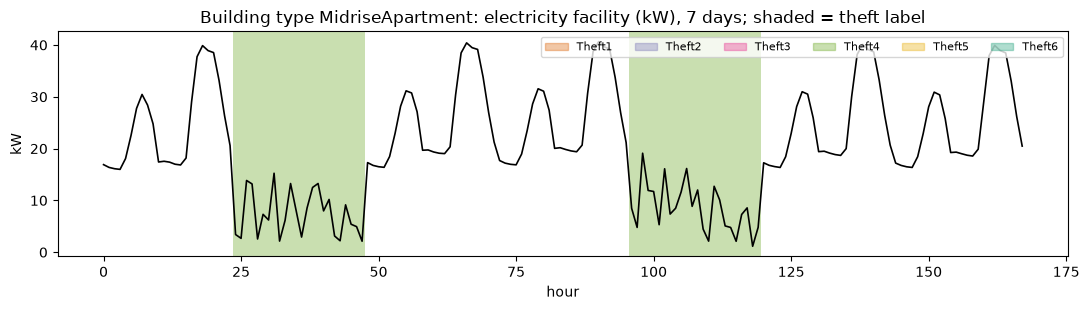

Class
FullServiceRestaurant     0.407
Hospital                  0.420
LargeHotel                0.424
LargeOffice               0.401
MediumOffice              0.394
MidriseApartment          0.410
OutPatient                0.419
PrimarySchool             0.395
QuickServiceRestaurant    0.404
SecondarySchool           0.415
SmallHotel                0.399
SmallOffice               0.420
Stand-aloneRetail         0.411
StripMall                 0.403
SuperMarket               0.403
Warehouse                 0.405


In [5]:
# Figure: one week of one building, theft readings shaded.
blk = df[df.series == 5].iloc[24 * 20: 24 * 27]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(np.arange(len(blk)), blk["Electricity"].values, color="k", lw=1.2)
cols = {"Theft1": "#d95f02", "Theft2": "#7570b3", "Theft3": "#e7298a", "Theft4": "#66a61e", "Theft5": "#e6ab02", "Theft6": "#1b9e77"}
for i, t in enumerate(blk.theft.values):
    if t != "Normal":
        ax.axvspan(i - .5, i + .5, color=cols[t], alpha=.35, lw=0)
ax.set_title(f"Building type {blk.Class.iloc[0]}: electricity facility (kW), 7 days; shaded = theft label")
ax.set_xlabel("hour"); ax.set_ylabel("kW")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=.35) for c in cols.values()]
ax.legend(handles, cols.keys(), ncol=6, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
print(df.groupby("Class").y.mean().round(3).to_string())

**Reading the figure.** Theft is applied in blocks of hours: a whole day (T1, T3, T4, T5, T6) or a window inside a day (T2).
Because the label sits on *single readings* and the model sees *one reading at a time* (10 numbers, no time context),
the task is "does this combination of ten end-use channels look physically plausible?". That is a much easier
problem for tree models (they can learn the arithmetic relations between channels) than a time-series task, which
is worth remembering when the results appear below.

## 2. Our own T7 and T8 generator (for the paper's "PT8" setting)

The public file stops at T6. Table 2 of the paper defines T7 and T8; we implement them and apply them to
randomly chosen **fully honest days** of the public file (all 24 readings labelled `Normal`), labelling only the
affected readings, exactly like the public T2 labels. The number of days replaced for each of T7 and T8 equals the
average number of whole days per full-day theft type already in the file, so the new types are as frequent as the others.

In [6]:
def make_pt8(df, seed):
    """Return a copy of df in which some honest days are replaced by T7 / T8 thefts (CHOICE: see the table above)."""
    rng = np.random.default_rng(seed)
    out = df.copy()
    X = out[FEATS].to_numpy(dtype=float).copy()
    theft = out.theft.to_numpy(dtype=object).copy()
    days = theft.reshape(-1, 24)                                 # one row per day (every block starts at a multiple of 24 hours)
    normal_days = np.where((days == "Normal").all(1))[0]         # fully honest days
    n_new = int(round(np.mean([(days == t).all(1).sum() for t in ["Theft1", "Theft3", "Theft4", "Theft5", "Theft6"]])))   # days per new type
    chosen = rng.choice(normal_days, size=2 * n_new, replace=False)
    for k, d in enumerate(chosen):
        s = int(d) * 24
        if k < n_new:                                            # T7: random window, random scaling inside it
            t_off = 4
            start = rng.integers(0, 24 - t_off); dur = rng.integers(t_off, 25); end = min(start + dur, 24)
            for h in range(start, end):
                X[s + h] *= rng.uniform(0.1, 0.8); theft[s + h] = "Theft7"
        else:                                                    # T8: one abrupt zero reading
            h = rng.integers(0, 24); X[s + h] = 0.0; theft[s + h] = "Theft8"
    out[FEATS] = X; out["theft"] = theft; out["y"] = (out.theft != "Normal").astype(int)
    return out, n_new
df8, n_new = make_pt8(df, SEED)
print("days replaced per new type:", n_new, "| PT8 theft share: %.3f" % df8.y.mean())
print(df8.theft.value_counts().to_string())

days replaced per new type: 1648 | PT8 theft share: 0.443
theft
Normal    312361
Theft1     51083
Theft3     44349
Theft4     41460
Theft6     35413
Theft5     33553
Theft2     22958
Theft7     17815
Theft8      1648


## 3. The classical baselines and the metrics

All competitors receive **exactly the same inputs** as the quantum model (the 10 standardised channels in the
consumption domain). The "LSTM" row of the paper is, according to its Table 4, a plain dense stack
(10-25-10-10-2); we build it with the same layers as the hybrid model but with the quantum layer replaced by a
`Dense(10, ReLU)`. Gradient-boosting models use their default-like settings (the paper tuned by trial and error).

In [7]:
def metrics(y, p_prob, thr=0.5):
    """Accuracy, precision, recall, F1 (theft = positive class) and ROC-AUC, as in equations (1)-(4) of the paper."""
    pred = (np.asarray(p_prob) >= thr).astype(int)
    m = dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0),
             rec=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
             auc=roc_auc_score(y, p_prob) if len(np.unique(y)) > 1 else float("nan"))
    m["cm"] = confusion_matrix(y, pred, labels=[0, 1])
    return m

def classical_models(seed):
    ms = {"RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=THREADS, random_state=seed),
          "SVC (rbf)": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed),
          "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=THREADS, random_state=seed, verbosity=0),
          "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.1, n_jobs=THREADS, random_state=seed, verbose=-1)}
    if HAVE_CATBOOST:
        ms["CatBoost"] = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.1, random_seed=seed, verbose=0, thread_count=THREADS)
    return ms

def score_of(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    d = model.decision_function(X)
    return 1 / (1 + np.exp(-d))                      # monotone map to (0, 1) for AUC / thresholding at 0

def fit_classical(Xtr, ytr, seed):
    out = {}
    for name, m in classical_models(seed).items():
        t = time.time(); m.fit(Xtr, ytr); out[name] = (m, time.time() - t)
    return out

## 4. The quantum layer: QVC-DRC in PennyLane

The core of the model (paper Fig. 1) is a **quantum variational circuit with data re-uploading**:

```
for block in 1..B:
    AngleEmbedding(inputs)                 # one RX(x_i) rotation per qubit, x = output of the classical layer
    StronglyEntanglingLayers(weights[block])   # Rot(phi, theta, omega) on every qubit + a ring of CNOTs
measure <Z> on every qubit                  # n numbers in [-1, 1] go to the next classical layer
```

Because the same inputs are written into the circuit again in every block, the circuit can represent much richer
functions of the inputs than a single embedding ("data re-uploading"). Below we first write the circuit exactly as a
PennyLane QNode (the reference), then a fast exact statevector simulator in PyTorch, and check that both give the same
outputs *and the same gradients*.

In [8]:
def make_qnode(n_qubits, n_blocks, n_layers):
    """Reference implementation: the QVC-DRC as a PennyLane QNode (differentiable through PyTorch)."""
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for b in range(n_blocks):
            qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="X")
            qml.StronglyEntanglingLayers(weights[b], wires=range(n_qubits))
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    return circuit

print(qml.draw(make_qnode(4, 2, 1), decimals=1)(torch.rand(4), torch.rand(2, 1, 4, 3)))

0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─╭AngleEmbedding(M0) ···
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0) ···
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0) ···
3: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─╰AngleEmbedding(M0) ···

0: ··· ─╭StronglyEntanglingLayers(M2)─┤  <Z>
1: ··· ─├StronglyEntanglingLayers(M2)─┤  <Z>
2: ··· ─├StronglyEntanglingLayers(M2)─┤  <Z>
3: ··· ─╰StronglyEntanglingLayers(M2)─┤  <Z>

M0 = 
tensor([0.8823, 0.9150, 0.3829, 0.9593])
M1 = 
tensor([[[0.3904, 0.6009, 0.2566],
         [0.7936, 0.9408, 0.1332],
         [0.9346, 0.5936, 0.8694],
         [0.5677, 0.7411, 0.4294]]])
M2 = 
tensor([[[0.8854, 0.5739, 0.2666],
         [0.6274, 0.2696, 0.4414],
         [0.2969, 0.8317, 0.1053],
         [0.2695, 0.3588, 0.1994]]])


In [9]:
def rot_mats(w):
    """qml.Rot(phi, theta, omega) as 2x2 complex matrices; w[..., 3] -> [..., 2, 2]."""
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    ct, st = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda a: torch.polar(torch.ones_like(a), a)
    U00 = e(-(phi + om) / 2) * ct; U01 = -e((phi - om) / 2) * st
    U10 = e(-(phi - om) / 2) * st; U11 = e((phi + om) / 2) * ct
    return torch.stack([torch.stack([U00, U01], -1), torch.stack([U10, U11], -1)], -2)

def rx_mats(x):
    """qml.RX(x) as 2x2 complex matrices; x[...] -> [..., 2, 2]."""
    c, s = torch.cos(x / 2).to(torch.complex64), torch.sin(x / 2).to(torch.complex64)
    z = -1j * s
    return torch.stack([torch.stack([c, z], -1), torch.stack([z, c], -1)], -2)

class FastDRC(nn.Module):
    """Exact statevector simulator of the QVC-DRC above (same circuit, same conventions as PennyLane).
    Gates are applied qubit by qubit to a (batch, 2^n) state; the CNOT ring is one index permutation. For one
    entangling layer per block, the Rot gate and the next embedding RX are merged into one 2x2 matrix per qubit."""
    def __init__(self, n_qubits=10, n_blocks=3, n_layers=1, init_std=0.1):
        super().__init__()
        self.n, self.nb, self.nl = n_qubits, n_blocks, n_layers
        self.weights = nn.Parameter(init_std * torch.randn(n_blocks, n_layers, n_qubits, 3))   # CHOICE: N(0, 0.1)
        n = n_qubits
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1                 # wire 0 = most significant bit
        self.register_buffer("zsign", torch.tensor(1 - 2 * bits, dtype=torch.float32))
        for r in sorted({(l % (n - 1)) + 1 for l in range(n_layers)}):                # StronglyEntanglingLayers ranges
            b = bits.copy()
            for w in range(n):
                b[:, (w + r) % n] ^= b[:, w]                                          # CNOT(w, w + r)
            new_idx = (b * (1 << (n - 1 - np.arange(n)))[None, :]).sum(1)
            inv = np.empty_like(new_idx); inv[new_idx] = idx
            self.register_buffer(f"perm_{r}", torch.tensor(inv, dtype=torch.long))

    def _apply(self, psi, U, q):
        B = psi.shape[0]
        psi = psi.reshape(B, 2 ** q, 2, 2 ** (self.n - q - 1))
        eq = "bij,blja->blia" if U.dim() == 3 else "ij,blja->blia"
        return torch.einsum(eq, U, psi).reshape(B, -1)

    def forward(self, x):
        B, n = x.shape[0], self.n
        RX = rx_mats(x)                                             # (B, n, 2, 2): the same embedding in every block
        psi = torch.zeros(B, 2 ** n, dtype=torch.complex64, device=x.device); psi[:, 0] = 1
        for b in range(self.nb):
            Rot = rot_mats(self.weights[b])                         # (n_layers, n, 2, 2)
            first = torch.matmul(Rot[0].unsqueeze(0), RX)           # Rot . RX(x) per sample and qubit
            for q in range(n):
                psi = self._apply(psi, first[:, q], q)
            for l in range(self.nl):
                if l > 0:
                    for q in range(n):
                        psi = self._apply(psi, Rot[l, q], q)
                psi = psi[:, getattr(self, f"perm_{(l % (n - 1)) + 1}")]
        return (psi.real ** 2 + psi.imag ** 2) @ self.zsign         # <Z_i> for every qubit

# ---- equivalence check against the PennyLane QNode (outputs AND gradients) ----
torch.manual_seed(0)
nq, nb, nl = 6, 3, 2
fast = FastDRC(nq, nb, nl, init_std=1.0)
xx = torch.rand(5, nq) * 3
w_ref = fast.weights.detach().double().clone().requires_grad_(True)
ref = torch.stack(make_qnode(nq, nb, nl)(xx.double(), w_ref), dim=1)
out = fast(xx)
ref.sum().backward(); out.sum().backward()
print("max |output difference| :", float((ref.float() - out).abs().max()))
print("max |gradient difference|:", float((w_ref.grad.float() - fast.weights.grad).abs().max()))
assert torch.allclose(ref.float(), out, atol=1e-5) and torch.allclose(w_ref.grad.float(), fast.weights.grad, atol=1e-4)
# ---- timing of one training step (batch 16, 10 qubits, 3 blocks, 1 layer) ----
xb = torch.rand(BATCH, 10)
tq = make_qnode(10, 3, 1); wq = torch.randn(3, 1, 10, 3, requires_grad=True); fq = FastDRC(10, 3, 1)
t0 = time.time()
for _ in range(3): torch.stack(tq(xb, wq), 1).sum().backward()
t_pl = (time.time() - t0) / 3
t0 = time.time()
for _ in range(10): fq(xb).sum().backward()
t_fast = (time.time() - t0) / 10
print(f"time per step: PennyLane QNode {t_pl*1000:.0f} ms | fast simulator {t_fast*1000:.0f} ms  (paper: ~300 ms on an i7)")

max |output difference| : 2.682209014892578e-07
max |gradient difference|: 8.940696716308594e-07


time per step: PennyLane QNode 552 ms | fast simulator 75 ms  (paper: ~300 ms on an i7)


## Quantum Circuit Architecture

The only quantum object of the paper is the **QVC-DRC** layer: `AngleEmbedding` (one RX per qubit) followed by `StronglyEntanglingLayers`
(a general rotation `Rot(phi, theta, omega)` on every qubit and a ring of CNOTs), repeated in `B` blocks, then `<Z>` on every qubit. The same circuit is used
in both domains (10 qubits, 3 blocks, 1 entangling layer per block); only the classical layers in front of it differ. The drawing
below is the **real PennyLane QNode** that is checked against the training simulator (decomposed to the gates that the device
executes). Assumptions where the paper is silent: one entangling layer per block, default CNOT range of 1, `AngleEmbedding` with X rotations,
Z-expectation read-out on all qubits, circuit weights ~ N(0, 0.1).

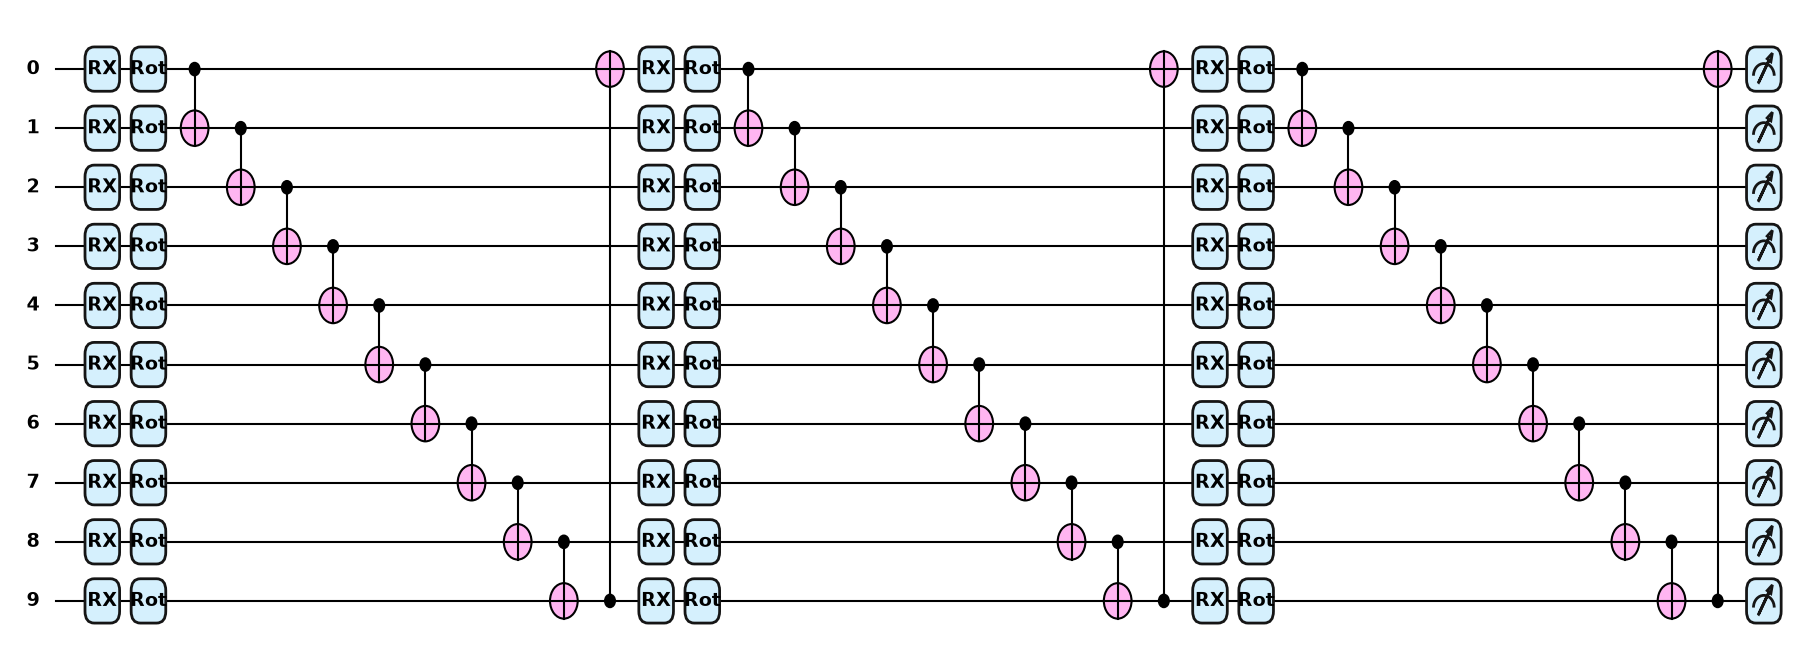

qubits: 10 | depth: 36 | gates: 90 {'RX': 30, 'Rot': 30, 'CNOT': 30}
trainable circuit parameters: 90 (= 3 blocks x 1 layer x 10 qubits x 3 angles); the 10 embedding angles are data, not parameters


training simulator == drawn QNode for the 10-qubit / 3-block / 1-layer circuit (outputs and gradients): OK


,sweep,setting,qubits,blocks,depth,gates,trainable_params
0,qubits (3 blocks),4,4,3,18,36,36
1,qubits (3 blocks),8,8,3,30,72,72
2,blocks (10 qubits),1,10,1,12,30,30
3,blocks (10 qubits),3,10,3,36,90,90


In [10]:
nq, nb, nl = N_QUBITS, N_BLOCKS, N_LAYERS
qn = make_qnode(nq, nb, nl)
x0, w0 = torch.rand(nq), torch.rand(nb, nl, nq, 3)
fig, ax = qml.draw_mpl(qn, level="device", decimals=None, style="pennylane")(x0, w0)
fig.set_size_inches(18, 6.5); plt.show()
res_ = qml.specs(qn, level="device")(x0, w0)["resources"]
print(f"qubits: {len(qn.device.wires)} | depth: {res_.depth} | gates: {res_.num_gates} {dict(res_.gate_types)}")
print(f"trainable circuit parameters: {w0.numel()} (= {nb} blocks x {nl} layer x {nq} qubits x 3 angles); the {nq} embedding angles are data, not parameters")
# equivalence of the drawn QNode with the simulator used for training, for exactly this architecture
fast_ = FastDRC(nq, nb, nl, init_std=1.0); xb_ = torch.rand(4, nq) * 3
w_ = fast_.weights.detach().double().clone().requires_grad_(True)
ref_ = torch.stack(qn(xb_.double(), w_), 1); out_ = fast_(xb_)
ref_.sum().backward(); out_.sum().backward()
assert torch.allclose(ref_.float(), out_, atol=1e-5) and torch.allclose(w_.grad.float(), fast_.weights.grad, atol=1e-4)
print("training simulator == drawn QNode for the 10-qubit / 3-block / 1-layer circuit (outputs and gradients): OK")
# the qubit / block sweeps of section 11 use the same gate pattern with other sizes
rows_ = []
for kind_, vals_ in [("qubits (3 blocks)", BUDGET["SWEEP_QUBITS"]), ("blocks (10 qubits)", BUDGET["SWEEP_BLOCKS"])]:
    for v_ in vals_:
        q_, b_ = (v_, N_BLOCKS) if kind_.startswith("qubits") else (N_QUBITS, v_)
        r2_ = qml.specs(make_qnode(q_, b_, N_LAYERS), level="device")(torch.rand(q_), torch.rand(b_, N_LAYERS, q_, 3))["resources"]
        rows_.append(dict(sweep=kind_, setting=v_, qubits=q_, blocks=b_, depth=r2_.depth, gates=r2_.num_gates, trainable_params=b_ * N_LAYERS * q_ * 3))
display(pd.DataFrame(rows_))

**Both implementations are the same circuit.** Outputs and gradients agree to floating-point accuracy, so every
number below is what the paper's PennyLane circuit would give; only the speed differs.

The hybrid network is: *classical layers -> QVC-DRC -> Dense(2) + softmax*. `quantum=False` swaps the QVC for a
`Dense(ReLU)` with the same width, which gives the paper's classical dense network.

In [11]:
class HybridNet(nn.Module):
    """classical layers (spec = list of (units, activation); units None = input size) -> QVC-DRC or Dense -> Dense(2)."""
    ACT = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "linear": nn.Identity}
    def __init__(self, in_dim, spec, n_qubits=10, n_blocks=3, n_layers=1, quantum=True):
        super().__init__()
        layers, d = [], in_dim
        for units, act in spec:
            units = in_dim if units is None else units
            layers += [nn.Linear(d, units), self.ACT[act]()]; d = units
        layers += [nn.Linear(d, n_qubits), nn.ReLU()]               # the layer before the QVC must have n_qubits neurons
        self.pre = nn.Sequential(*layers)
        self.mid = FastDRC(n_qubits, n_blocks, n_layers) if quantum else nn.Sequential(nn.Linear(n_qubits, n_qubits), nn.ReLU())
        self.out = nn.Linear(n_qubits, 2)                           # decision layer, softmax inside the loss
    def forward(self, x):
        return self.out(self.mid(self.pre(x)))

# Table 4 (consumption): Input 10 ReLU, Dense 25 ReLU, Dense 10 ReLU, [QVC-DRC 10 qubits | Dense 10 ReLU], Output 2 softmax
SPEC_CONS = [(10, "relu"), (25, "relu")]
# Table 8 (net metering): Input 24 linear, Dense 128 linear, Dense 128 sigmoid x2, Dense 256 sigmoid, Dense 18 ReLU -> we use n_qubits
SPEC_NM = [(None, "linear"), (128, "linear"), (128, "sigmoid"), (128, "sigmoid"), (256, "sigmoid")]

def train_hybrid(Xtr, ytr, Xva, yva, spec, quantum=True, epochs=5, seed=0, n_qubits=N_QUBITS, n_blocks=N_BLOCKS,
                 n_layers=N_LAYERS, lr=LR, batch=BATCH, tag="", verbose=True):
    """Cross-entropy training with mini-batches of 16; keeps the epoch with the lowest validation loss."""
    torch.manual_seed(seed); np.random.seed(seed)
    net = HybridNet(Xtr.shape[1], spec, n_qubits, n_blocks, n_layers, quantum)
    opt = torch.optim.Adam(net.parameters(), lr=lr)                 # CHOICE: Adam instead of the paper's SGD (see table above)
    lossf = nn.CrossEntropyLoss()
    Xt, yt = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.long)
    Xv, yv = torch.tensor(Xva, dtype=torch.float32), torch.tensor(yva, dtype=torch.long)
    g = torch.Generator().manual_seed(seed)
    best, best_state, hist, t0 = (1e9, None), None, [], time.time()
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt), generator=g); run = 0.0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); loss = lossf(net(Xt[b]), yt[b]); loss.backward(); opt.step(); run += loss.item() * len(b)
        net.eval()
        with torch.no_grad():
            lv = lossf(net(Xv), yv).item(); acc = (net(Xv).argmax(1) == yv).float().mean().item()
        hist.append((run / len(Xt), lv, acc))
        if lv < best[0]:
            best = (lv, ep); best_state = {k: v.clone() for k, v in net.state_dict().items()}
        if verbose and (ep == 0 or (ep + 1) % max(1, epochs // 5) == 0 or ep == epochs - 1):
            print(f"  {tag} epoch {ep+1:3d}/{epochs}  train loss {run/len(Xt):.3f}  val loss {lv:.3f}  val acc {acc:.3f}  ({time.time()-t0:.0f}s)")
    net.load_state_dict(best_state); net.eval()
    return net, dict(hist=np.array(hist), best_epoch=best[1] + 1, train_time=time.time() - t0, sec_per_epoch=(time.time() - t0) / epochs)

@torch.no_grad()
def predict_net(net, X, chunk=2048):
    out = []
    for i in range(0, len(X), chunk):
        out.append(torch.softmax(net(torch.tensor(X[i:i + chunk], dtype=torch.float32)), 1)[:, 1].numpy())
    return np.concatenate(out)

## 5. Consumption domain: sampling, splitting, training (PT6)

For every random seed we draw `N_ROWS` hourly readings from the public file, split them 75 / 15 / 10 (stratified),
fit the `StandardScaler` **on the training part only**, train the hybrid quantum network (FH-QVC-DRC) and the five
baselines on the same standardised ten inputs, and score the 10 % test part. A further set of readings that no model
ever saw (`EVAL_ROWS`) is kept aside for the per-building-type tables (the 10 % test split alone has only a few
readings per building type).

In [12]:
def prepare_cons(dfx, seed, n_rows, eval_rows, grouped=False):
    rng = np.random.default_rng(seed)
    X = dfx[FEATS].to_numpy(float); y = dfx.y.to_numpy()
    if grouped:     # leak check: whole building time series are held out (one of the four series of every building type)
        ser = dfx.series.to_numpy()
        held_series = set(dfx.groupby("Class").series.max().tolist())     # the last of the 4 series of every building type
        pool_idx = np.where(~np.isin(ser, list(held_series)))[0]; ev_pool = np.where(np.isin(ser, list(held_series)))[0]
    else:
        pool_idx = np.arange(len(dfx)); ev_pool = None
    idx = rng.choice(pool_idx, n_rows, replace=False)
    rest = ev_pool if grouped else np.setdiff1d(pool_idx, idx)
    eidx = rng.choice(rest, min(eval_rows, len(rest)), replace=False)
    Xtr, Xr, ytr, yr = train_test_split(X[idx], y[idx], test_size=VAL_FRAC + TEST_FRAC, random_state=seed, stratify=y[idx])
    Xva, Xte, yva, yte = train_test_split(Xr, yr, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=seed, stratify=yr)
    sc = StandardScaler().fit(Xtr)                                       # fitted on the training split only
    f = lambda a: sc.transform(a)
    return dict(Xtr=f(Xtr), ytr=ytr, Xva=f(Xva), yva=yva, Xte=f(Xte), yte=yte, Xev=f(X[eidx]), yev=y[eidx],
                cev=dfx.Class.to_numpy()[eidx], tev=dfx.theft.to_numpy()[eidx], scaler=sc)

def run_domain(dfx, domain, seeds, n_rows, epochs, eval_rows, grouped=False, keep_first=True):
    rows, keep = [], {}
    for si, seed in enumerate(seeds):
        d = prepare_cons(dfx, seed, n_rows, eval_rows, grouped)
        print(f"[{domain}] seed {seed}: train {len(d['ytr'])}, val {len(d['yva'])}, test {len(d['yte'])}, "
              f"eval pool {len(d['yev'])}, theft share in test {d['yte'].mean():.2f}")
        models = {}
        net, info = train_hybrid(d["Xtr"], d["ytr"], d["Xva"], d["yva"], SPEC_CONS, True, epochs, seed, tag="FH-QVC-DRC")
        models["FH-QVC-DRC (quantum)"] = (net, info["train_time"], info)
        cnet, cinfo = train_hybrid(d["Xtr"], d["ytr"], d["Xva"], d["yva"], SPEC_CONS, False, epochs, seed, tag="dense   ", verbose=False)
        models["Dense net (paper's 'LSTM')"] = (cnet, cinfo["train_time"], cinfo)
        for name, (m, tt) in fit_classical(d["Xtr"], d["ytr"], seed).items():
            models[name] = (m, tt, None)
        preds = {}
        for name, (m, tt, info_) in models.items():
            score = (lambda X, m=m: predict_net(m, X)) if isinstance(m, nn.Module) else (lambda X, m=m: score_of(m, X))
            t0 = time.time(); p = score(d["Xte"]); t_pred = time.time() - t0
            r = metrics(d["yte"], p); r.update(domain=domain, seed=seed, model=name, train_time=tt, pred_time=t_pred)
            pe = score(d["Xev"]); pm = metrics(d["yev"], pe)             # the large held-out pool: a far less noisy estimate
            r.update(acc_pool=pm["acc"], f1_pool=pm["f1"], auc_pool=pm["auc"], cm_pool=pm["cm"])
            rows.append(r)
            if si == 0:
                preds[name] = pe
        if si == 0 and keep_first:
            keep = dict(data=d, models=models, eval_pred=preds)
    return pd.DataFrame(rows), keep

def summarise(res, cols=("acc", "prec", "rec", "f1", "auc")):
    """mean +/- std over seeds of the test-split metrics, plus accuracy / F1 on the large held-out pool of readings."""
    g = res.groupby("model", sort=False)
    out = pd.DataFrame({c: g[c].mean().round(3).astype(str) + " +/- " + g[c].std(ddof=0).fillna(0).round(3).astype(str) for c in cols})
    if "acc_pool" in res:
        out["acc (pool)"] = g["acc_pool"].mean().round(3); out["F1 (pool)"] = g["f1_pool"].mean().round(3)
    out["train s"] = g["train_time"].mean().round(1)
    return out

In [13]:
t0 = time.time()
res6, keep6 = run_domain(df, "PT6", BUDGET["SEEDS"], BUDGET["N_ROWS"], BUDGET["EPOCHS"], BUDGET["EVAL_ROWS"])
print("PT6 block done in %.0f s" % (time.time() - t0))
display(summarise(res6))

[PT6] seed 42: train 1500, val 300, test 200, eval pool 6000, theft share in test 0.42


  FH-QVC-DRC epoch   1/5  train loss 0.680  val loss 0.667  val acc 0.583  (12s)


  FH-QVC-DRC epoch   2/5  train loss 0.661  val loss 0.639  val acc 0.633  (20s)


  FH-QVC-DRC epoch   3/5  train loss 0.642  val loss 0.627  val acc 0.663  (27s)


  FH-QVC-DRC epoch   4/5  train loss 0.636  val loss 0.632  val acc 0.653  (33s)


  FH-QVC-DRC epoch   5/5  train loss 0.635  val loss 0.629  val acc 0.653  (39s)


PT6 block done in 116 s


,acc,prec,rec,f1,auc,acc (pool),F1 (pool),train s
model,,,,,,,,
FH-QVC-DRC (quantum),0.535 +/- 0.0,0.448 +/- 0.0,0.464 +/- 0.0,0.456 +/- 0.0,0.568 +/- 0.0,0.629,0.556,39.2
Dense net (paper's 'LSTM'),0.515 +/- 0.0,0.437 +/- 0.0,0.536 +/- 0.0,0.481 +/- 0.0,0.57 +/- 0.0,0.616,0.558,2.0
RandomForest,0.885 +/- 0.0,0.896 +/- 0.0,0.821 +/- 0.0,0.857 +/- 0.0,0.929 +/- 0.0,0.886,0.851,1.7
SVC (rbf),0.575 +/- 0.0,0.495 +/- 0.0,0.536 +/- 0.0,0.514 +/- 0.0,0.621 +/- 0.0,0.643,0.581,0.1
XGBoost,0.895 +/- 0.0,0.889 +/- 0.0,0.857 +/- 0.0,0.873 +/- 0.0,0.938 +/- 0.0,0.891,0.859,19.9
LightGBM,0.88 +/- 0.0,0.885 +/- 0.0,0.821 +/- 0.0,0.852 +/- 0.0,0.929 +/- 0.0,0.890,0.858,37.2


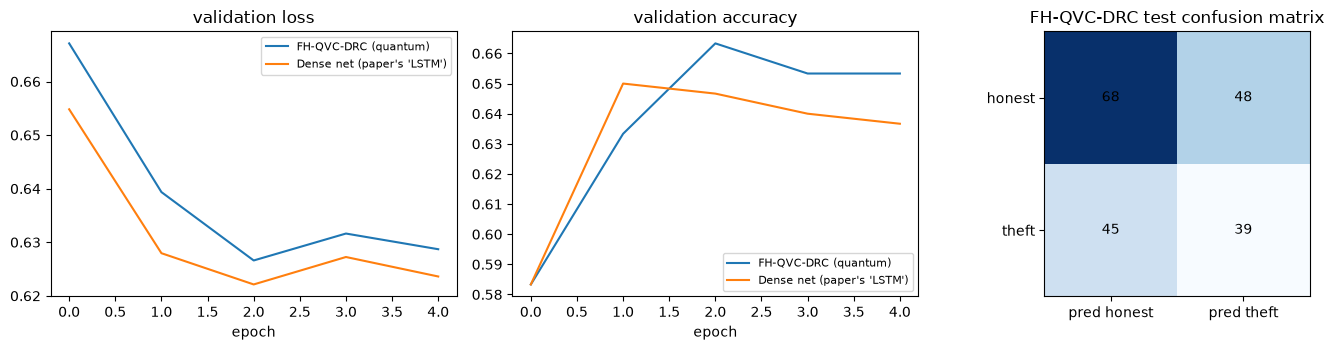

best classical baseline on the same test split: XGBoost acc 0.895  f1 0.873
confusion matrix of that baseline:
 [[107   9]
 [ 12  72]]


In [14]:
# Training curves and confusion matrices (first seed). Theft = positive class.
d6, m6 = keep6["data"], keep6["models"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for name, c in [("FH-QVC-DRC (quantum)", "C0"), ("Dense net (paper's 'LSTM')", "C1")]:
    h = m6[name][2]["hist"]
    ax[0].plot(h[:, 1], c, label=name); ax[1].plot(h[:, 2], c, label=name)
ax[0].set_title("validation loss"); ax[1].set_title("validation accuracy")
for a in ax[:2]:
    a.set_xlabel("epoch"); a.legend(fontsize=8)
best_cls = res6[res6.seed == BUDGET["SEEDS"][0]].query("model not in ['FH-QVC-DRC (quantum)', \"Dense net (paper's 'LSTM')\"]").sort_values("acc").iloc[-1]
cm = res6[(res6.seed == BUDGET["SEEDS"][0]) & (res6.model == "FH-QVC-DRC (quantum)")].iloc[0]["cm"]
ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("FH-QVC-DRC test confusion matrix")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, int(cm[i, j]), ha="center", va="center", color="k")
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["pred honest", "pred theft"]); ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(["honest", "theft"])
plt.tight_layout(); plt.show()
print("best classical baseline on the same test split:", best_cls["model"], "acc %.3f  f1 %.3f" % (best_cls["acc"], best_cls["f1"]))
print("confusion matrix of that baseline:\n", best_cls["cm"])

## 6. Per-building-type results (paper Tables 6 and 7)

The paper reports accuracy and F1 *per building type* for the first six theft types (PT6) and for all eight (PT8).
We score the models trained above on the held-out evaluation readings of each building type (the models are trained on
all types together, as we read the paper). Building types appear in the paper's order.

In [15]:
def per_class_table(keep, models_show):
    d = keep["data"]; rows = {}
    for cls in sorted(set(d["cev"])):
        mk = d["cev"] == cls; r = {}
        for name in models_show:
            p = (keep["eval_pred"][name] >= 0.5).astype(int)
            r[(name, "ACC")] = accuracy_score(d["yev"][mk], p[mk]); r[(name, "F1")] = f1_score(d["yev"][mk], p[mk], zero_division=0)
        rows[cls] = r
    t = pd.DataFrame(rows).T; t.columns = pd.MultiIndex.from_tuples(t.columns)
    t.loc["MEAN"] = t.mean()
    return t.round(2)

SHOW = ["FH-QVC-DRC (quantum)", "Dense net (paper's 'LSTM')", "XGBoost", "LightGBM"] + (["CatBoost"] if HAVE_CATBOOST else [])
tab6 = per_class_table(keep6, SHOW)
display(tab6)

FH-QVC-DRC (quantum)       Dense net (paper's 'LSTM')  \
                                        ACC    F1                        ACC   
FullServiceRestaurant                  0.69  0.60                       0.70   
Hospital                               0.63  0.30                       0.62   
LargeHotel                             0.66  0.35                       0.66   
LargeOffice                            0.67  0.35                       0.67   
MediumOffice                           0.52  0.51                       0.54   
MidriseApartment                       0.56  0.63                       0.54   
OutPatient                             0.78  0.62                       0.79   
PrimarySchool                          0.64  0.53                       0.52   
QuickServiceRestaurant                 0.68  0.61                       0.63   
SecondarySchool                        0.70  0.44                       0.70   
SmallHotel                             0.72  0.59                       0.70   
SmallOffice                            0.42  0.59                       0.42   
Stand-aloneRetail                      0.64  0.63                       0.64   
StripMall                              0.64  0.64                       0.59   
SuperMarket                            0.59  0.49                       0.59   
Warehouse                              0.57  0.63                       0.57   
MEAN                                   0.63  0.53                       0.62   

                             XGBoost       LightGBM        
                          F1     ACC    F1      ACC    F1  
FullServiceRestaurant   0.63    0.92  0.90     0.90  0.87  
Hospital                0.28    0.90  0.88     0.92  0.90  
LargeHotel              0.36    0.93  0.91     0.92  0.91  
LargeOffice             0.35    0.89  0.85     0.89  0.86  
MediumOffice            0.55    0.86  0.79     0.88  0.82  
MidriseApartment        0.63    0.83  0.77     0.84  0.78  
OutPatient              0.64    0.95  0.94     0.95  0.93  
PrimarySchool           0.46    0.91  0.88     0.90  0.87  
QuickServiceRestaurant  0.59    0.87  0.82     0.86  0.82  
SecondarySchool         0.45    0.86  0.83     0.84  0.81  
SmallHotel              0.58    0.87  0.79     0.88  0.82  
SmallOffice             0.59    0.95  0.94     0.95  0.94  
Stand-aloneRetail       0.66    0.88  0.84     0.91  0.88  
StripMall               0.63    0.86  0.83     0.85  0.82  
SuperMarket             0.49    0.90  0.87     0.91  0.88  
Warehouse               0.64    0.87  0.84     0.85  0.82  
MEAN                    0.53    0.89  0.86     0.89  0.86

## 7. The paper's "PT8" setting (T1-T8, with our own T7/T8)

Same pipeline on the data set in which our T7 and T8 are added (section 2). This is an *approximation* of the paper's
PT8 data, because the authors' generator and their raw (unmodified) series are not public.

In [16]:
t0 = time.time()
res8, keep8 = run_domain(df8, "PT8", BUDGET["SEEDS"][:1], BUDGET["N_ROWS"], BUDGET["EPOCHS"], BUDGET["EVAL_ROWS"])
print("PT8 block done in %.0f s" % (time.time() - t0))
display(summarise(res8))
tab7 = per_class_table(keep8, SHOW)
display(tab7)

[PT8] seed 42: train 1500, val 300, test 200, eval pool 6000, theft share in test 0.46


  FH-QVC-DRC epoch   1/5  train loss 0.691  val loss 0.679  val acc 0.550  (9s)


  FH-QVC-DRC epoch   2/5  train loss 0.665  val loss 0.651  val acc 0.633  (18s)


  FH-QVC-DRC epoch   3/5  train loss 0.650  val loss 0.658  val acc 0.550  (25s)


  FH-QVC-DRC epoch   4/5  train loss 0.644  val loss 0.642  val acc 0.647  (34s)


  FH-QVC-DRC epoch   5/5  train loss 0.638  val loss 0.645  val acc 0.613  (43s)


PT8 block done in 60 s


,acc,prec,rec,f1,auc,acc (pool),F1 (pool),train s
model,,,,,,,,
FH-QVC-DRC (quantum),0.645 +/- 0.0,0.619 +/- 0.0,0.571 +/- 0.0,0.594 +/- 0.0,0.685 +/- 0.0,0.626,0.577,42.7
Dense net (paper's 'LSTM'),0.645 +/- 0.0,0.6 +/- 0.0,0.659 +/- 0.0,0.628 +/- 0.0,0.689 +/- 0.0,0.618,0.590,3.1
RandomForest,0.91 +/- 0.0,0.94 +/- 0.0,0.857 +/- 0.0,0.897 +/- 0.0,0.961 +/- 0.0,0.884,0.862,2.1
SVC (rbf),0.65 +/- 0.0,0.6 +/- 0.0,0.692 +/- 0.0,0.643 +/- 0.0,0.698 +/- 0.0,0.630,0.623,0.2
XGBoost,0.91 +/- 0.0,0.962 +/- 0.0,0.835 +/- 0.0,0.894 +/- 0.0,0.967 +/- 0.0,0.899,0.880,1.9
LightGBM,0.91 +/- 0.0,0.92 +/- 0.0,0.879 +/- 0.0,0.899 +/- 0.0,0.95 +/- 0.0,0.894,0.874,1.9


FH-QVC-DRC (quantum)       Dense net (paper's 'LSTM')  \
                                        ACC    F1                        ACC   
FullServiceRestaurant                  0.66  0.59                       0.68   
Hospital                               0.65  0.43                       0.61   
LargeHotel                             0.64  0.35                       0.70   
LargeOffice                            0.64  0.37                       0.65   
MediumOffice                           0.54  0.53                       0.53   
MidriseApartment                       0.56  0.66                       0.50   
OutPatient                             0.76  0.63                       0.77   
PrimarySchool                          0.74  0.63                       0.51   
QuickServiceRestaurant                 0.67  0.63                       0.63   
SecondarySchool                        0.65  0.46                       0.68   
SmallHotel                             0.72  0.62                       0.75   
SmallOffice                            0.46  0.63                       0.46   
Stand-aloneRetail                      0.61  0.63                       0.64   
StripMall                              0.61  0.64                       0.61   
SuperMarket                            0.57  0.50                       0.60   
Warehouse                              0.55  0.63                       0.59   
MEAN                                   0.63  0.56                       0.62   

                             XGBoost       LightGBM        
                          F1     ACC    F1      ACC    F1  
FullServiceRestaurant   0.63    0.92  0.90     0.92  0.90  
Hospital                0.32    0.91  0.90     0.89  0.88  
LargeHotel              0.52    0.97  0.96     0.94  0.93  
LargeOffice             0.34    0.89  0.87     0.88  0.86  
MediumOffice            0.53    0.89  0.83     0.85  0.79  
MidriseApartment        0.63    0.83  0.79     0.83  0.79  
OutPatient              0.68    0.96  0.95     0.96  0.95  
PrimarySchool           0.51    0.91  0.89     0.88  0.86  
QuickServiceRestaurant  0.62    0.92  0.90     0.93  0.91  
SecondarySchool         0.48    0.85  0.82     0.85  0.84  
SmallHotel              0.69    0.91  0.87     0.90  0.86  
SmallOffice             0.63    0.94  0.94     0.94  0.93  
Stand-aloneRetail       0.67    0.89  0.86     0.91  0.89  
StripMall               0.67    0.86  0.85     0.86  0.85  
SuperMarket             0.55    0.91  0.89     0.90  0.88  
Warehouse               0.66    0.85  0.83     0.86  0.84  
MEAN                    0.57    0.90  0.88     0.89  0.87

## 8. Leakage check: hold out whole building series

In the paper (and above) readings from the same building and the same day can land in both the training and the test
split. Neighbouring hours of one day share a label and are similar, so a **random split of readings can flatter every
model**. Here the test readings come from building time series that never appear in training (the fourth series of each of
the 16 building types is held out).

In [17]:
t0 = time.time()
resg, keepg = run_domain(df, "PT6 grouped split", BUDGET["SEEDS"][:1], BUDGET["N_ROWS"], BUDGET["EPOCHS"], min(BUDGET["EVAL_ROWS"], 6000),
                         grouped=True, keep_first=True)
# in the grouped run the held-out series play the role of the test set: score the models on that pool
dg = keepg["data"]; rows = []
for name, (m, tt, info) in keepg["models"].items():
    p = keepg["eval_pred"][name]
    r = metrics(dg["yev"], p); r.update(domain="PT6 grouped split", seed=BUDGET["SEEDS"][0], model=name, train_time=tt, pred_time=0.0)
    r.update(acc_pool=r["acc"], f1_pool=r["f1"], auc_pool=r["auc"]); rows.append(r)
resg = pd.DataFrame(rows)
print("grouped-split block done in %.0f s" % (time.time() - t0))
display(summarise(resg))

[PT6 grouped split] seed 42: train 1500, val 300, test 200, eval pool 6000, theft share in test 0.40


  FH-QVC-DRC epoch   1/5  train loss 0.673  val loss 0.668  val acc 0.600  (11s)


  FH-QVC-DRC epoch   2/5  train loss 0.663  val loss 0.662  val acc 0.600  (22s)


  FH-QVC-DRC epoch   3/5  train loss 0.651  val loss 0.660  val acc 0.600  (32s)


  FH-QVC-DRC epoch   4/5  train loss 0.644  val loss 0.654  val acc 0.660  (43s)


  FH-QVC-DRC epoch   5/5  train loss 0.637  val loss 0.656  val acc 0.597  (51s)


grouped-split block done in 97 s


,acc,prec,rec,f1,auc,acc (pool),F1 (pool),train s
model,,,,,,,,
FH-QVC-DRC (quantum),0.656 +/- 0.0,0.943 +/- 0.0,0.174 +/- 0.0,0.294 +/- 0.0,0.686 +/- 0.0,0.656,0.294,51.2
Dense net (paper's 'LSTM'),0.648 +/- 0.0,0.639 +/- 0.0,0.329 +/- 0.0,0.435 +/- 0.0,0.681 +/- 0.0,0.648,0.435,3.4
RandomForest,0.882 +/- 0.0,0.921 +/- 0.0,0.779 +/- 0.0,0.844 +/- 0.0,0.922 +/- 0.0,0.882,0.844,2.0
SVC (rbf),0.6 +/- 0.0,0.793 +/- 0.0,0.037 +/- 0.0,0.071 +/- 0.0,0.721 +/- 0.0,0.600,0.071,0.2
XGBoost,0.897 +/- 0.0,0.907 +/- 0.0,0.835 +/- 0.0,0.87 +/- 0.0,0.931 +/- 0.0,0.897,0.870,16.9
LightGBM,0.898 +/- 0.0,0.907 +/- 0.0,0.838 +/- 0.0,0.871 +/- 0.0,0.93 +/- 0.0,0.898,0.871,15.4


## 9. Net-metering domain: Ausgrid solar homes, weather and attacks (paper Table 3, Table 9)

**Data.** The Ausgrid "Solar home electricity data" (300 homes in Sydney / New South Wales, half-hourly, 1 July 2010 - 30 June 2013,
Creative Commons Attribution) gives for every home a *consumption* channel (GC) and a *generation* channel (GG).
Ausgrid no longer hosts the files; we download the self-hosted archive copy of Pierre Haessig (it contains the unchanged
Ausgrid CSV files, SHA-256 checked below). A net-metering smart meter reports only the difference, so the **net reading =
consumption - generation** (negative when the panels produce more than the home uses), summed to **hourly** values.

**Weather.** The paper takes irradiance and temperature from Solcast (commercial). We use the free Open-Meteo ERA5 reanalysis for Sydney
(shortwave radiation and 2 m temperature, hourly, no key).

**Customers.** The paper keeps 31 clean customers with 1096 days; we draw 31 customers (seeded) among those with all 1096 days, no missing
value and no negative reading.

In [18]:
AUS_PATH = os.path.join(DATA_DIR, "Ausgrid_solar_home_data.zip")
AUS_URL  = "https://pierreh.eu/downloads/Ausgrid_solar_home_data.zip"
AUS_SHA  = "5a766f52b6c8b3b72730380f4422e478934bc94640a4b089dd0e0e3c055c5d82"
download(AUS_URL, AUS_PATH, AUS_SHA)

def read_ausgrid(path):
    frames = []
    with zipfile.ZipFile(path) as z:
        for fn in ["Solar home 2010-2011.csv", "Solar home 2011-2012.csv", "Solar home 2012-2013.csv"]:
            with z.open(fn) as f:
                d = pd.read_csv(f, skiprows=1)                       # first line is a title
            d = d[d["Consumption Category"].isin(["GC", "GG"])]
            try:
                d["date"] = pd.to_datetime(d["date"], format="%d-%b-%y")      # the three files use two date formats
            except ValueError:
                d["date"] = pd.to_datetime(d["date"], format="%d/%m/%Y")
            frames.append(d)
    return pd.concat(frames, ignore_index=True)

t0 = time.time()
aus = read_ausgrid(AUS_PATH)
HH = [c for c in aus.columns if ":" in c]                             # 48 half-hour columns
dates = pd.date_range("2010-07-01", "2013-06-30", freq="D"); ND = len(dates)       # 1096 days
cnt = aus.groupby(["Customer", "Consumption Category"]).date.nunique().unstack()
full = cnt.index[(cnt.GC == ND) & (cnt.GG == ND)]
def block(cat, cust):
    d = aus[(aus["Consumption Category"] == cat) & (aus.Customer == cust)].sort_values("date")
    return d[HH].to_numpy(float).reshape(ND, 24, 2).sum(-1)           # half-hours -> hourly (kWh per hour = average kW)
valid, NETS, CMAX = [], [], []
for c in full:
    gc, gg = block("GC", c), block("GG", c)
    if np.isfinite(gc).all() and np.isfinite(gg).all() and (gc >= 0).all() and (gg >= 0).all() and (gc.sum(1) > 0).mean() > 0.99:
        valid.append(c); NETS.append(gc - gg); CMAX.append(float(aus[aus.Customer == c]["Generator Capacity"].iloc[0]))
print(f"customers with {ND} complete days: {len(full)} | clean: {len(valid)} | read in {time.time()-t0:.0f} s")
pick = np.random.default_rng(SEED).choice(len(valid), 31, replace=False)      # CHOICE: 31 customers like the paper
NET = np.stack([NETS[i] for i in pick]); CMAX = np.array([CMAX[i] for i in pick]); CUST = np.array([valid[i] for i in pick])
print("net readings tensor (customers, days, hours):", NET.shape, "| share of negative hourly readings: %.2f" % (NET < 0).mean())

# --- weather (Open-Meteo ERA5, Sydney); cached as JSON ---
wpath = os.path.join(DATA_DIR, "openmeteo_sydney_2010-07-01_2013-06-30.json")
if not os.path.exists(wpath):
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=180, params=dict(
        latitude=-33.87, longitude=151.21, start_date="2010-07-01", end_date="2013-06-30",
        hourly="temperature_2m,shortwave_radiation", timezone="Australia/Brisbane"))      # CHOICE: UTC+10 all year (no daylight saving)
    r.raise_for_status(); json.dump(r.json()["hourly"], open(wpath, "w"))
W = json.load(open(wpath))
IRR = np.array(W["shortwave_radiation"], float).reshape(ND, 24) / 1000.0     # kW/m2
TMP = np.array(W["temperature_2m"], float).reshape(ND, 24)
DOW = dates.dayofweek.to_numpy()                                              # CHOICE: day = day of week
SEASON = np.select([dates.month.isin([12, 1, 2]), dates.month.isin([3, 4, 5]), dates.month.isin([6, 7, 8])], [0, 1, 2], 3)  # southern hemisphere
print("irradiance max %.2f kW/m2, temperature range %.1f..%.1f C, missing %d" % (IRR.max(), TMP.min(), TMP.max(), int(np.isnan(TMP).sum())))

Ausgrid_solar_home_data.zip sha256 OK


customers with 1096 complete days: 299 | clean: 297 | read in 36 s
net readings tensor (customers, days, hours): (31, 1096, 24) | share of negative hourly readings: 0.20
irradiance max 1.11 kW/m2, temperature range 4.4..39.2 C, missing 0


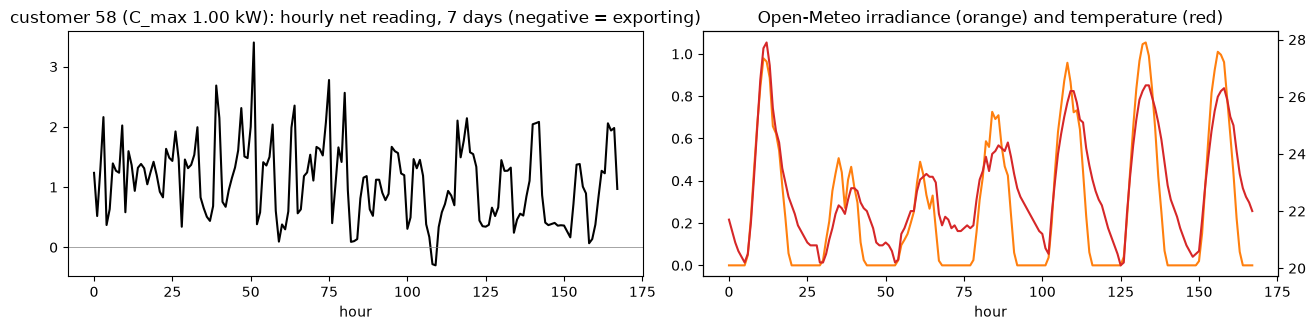

correlation of hourly net reading with irradiance: -0.40 | with temperature: -0.19  (paper Fig. 4: -0.56 and -0.70, on 7 sample points)


In [19]:
# Figure: one customer, one week of net readings plus the weather inputs of stage 2
c0, d0 = 0, 200
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(NET[c0, d0:d0 + 7].reshape(-1), "k"); ax[0].axhline(0, color="gray", lw=.5)
ax[0].set_title(f"customer {CUST[c0]} (C_max {CMAX[c0]:.2f} kW): hourly net reading, 7 days (negative = exporting)"); ax[0].set_xlabel("hour")
ax[1].plot(IRR[d0:d0 + 7].reshape(-1), "C1", label="irradiance (kW/m2)"); ax2 = ax[1].twinx(); ax2.plot(TMP[d0:d0 + 7].reshape(-1), "C3", label="temperature (C)")
ax[1].set_title("Open-Meteo irradiance (orange) and temperature (red)"); ax[1].set_xlabel("hour")
plt.tight_layout(); plt.show()
print("correlation of hourly net reading with irradiance: %.2f | with temperature: %.2f  (paper Fig. 4: -0.56 and -0.70, on 7 sample points)" % (
      np.corrcoef(NET[:, :, :].reshape(-1), np.tile(IRR.reshape(-1), len(NET)))[0, 1], np.corrcoef(NET.reshape(-1), np.tile(TMP.reshape(-1), len(NET)))[0, 1]))

## 10. The four false-reading attacks (Table 3) and the three stages

Notation: TR_t is the true net reading of hour t, C_max the panel capacity. A customer **gains** by making
positive readings smaller (pay less) and negative readings more negative (be paid more for exported energy).

| # | Type | Consumption > generation (TR_t > 0) | Consumption < generation (TR_t <= 0) |
|---|---|---|---|
| 1 | intermittent | b_t * TR_t inside a random window, TR_t outside | -max(p_t * C_max, abs(TR_t)) inside, TR_t outside |
| 2 | scaling | alpha * TR_t | -min(abs(beta * TR_t), C_max) |
| 3 | time-varying scaling | alpha_t * TR_t | -min(abs(beta_t * TR_t), C_max) |
| 4 | history based | M1_t * min(PR, TR_t) | -M2_t * max(abs(NR), abs(TR_t)) |

PR / NR are the last previous positive / negative true reading. Parameter ranges are our CHOICE (table at the top).
Weather, C_max and day/season features are *not* falsified; only the 24 net readings are.

**Stages (as in the paper).** Stage 1: the 24 net readings. Stage 2: + 24 irradiance values + 24 temperatures (72 inputs).
Stage 3: + C_max, day of week, season (75 inputs).

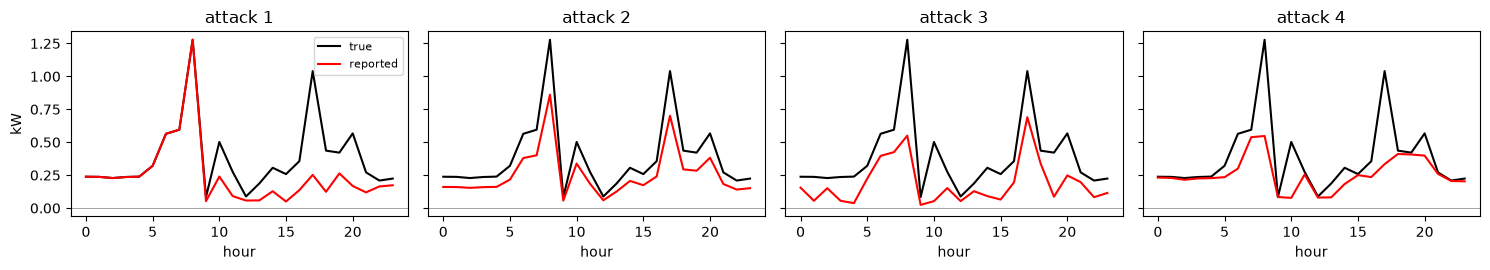

In [20]:
def attack_day(tr, cmax, kind, rng):
    """Apply attack `kind` (1..4) of Table 3 to a 24-vector of true net readings."""
    pos = tr > 0; out = tr.copy(); t = np.arange(24)
    if kind == 1:
        win = (t >= (s := rng.integers(0, 20))) & (t <= min(s + rng.integers(4, 24), 23))          # random window of 4-24 h
        b = rng.uniform(0.1, 0.8, 24); p = rng.uniform(0.5, 1.0, 24)
        att = np.where(pos, b * tr, -np.maximum(p * cmax, np.abs(tr)))
        out = np.where(win, att, tr)
    elif kind in (2, 3):
        shape = () if kind == 2 else (24,)
        a = rng.uniform(0.1, 0.8, shape); be = rng.uniform(1.0, 3.0, shape)
        out = np.where(pos, a * tr, -np.minimum(np.abs(be * tr), cmax))
    else:
        M1 = rng.uniform(0.9, 1.0, 24); M2 = rng.uniform(1.0, 1.1, 24)
        pr = nr = None
        for h in range(24):
            if pos[h]:
                pr = tr[h] if pr is None else pr
                out[h] = M1[h] * min(pr, tr[h]); pr = tr[h]
            else:
                nr = tr[h] if nr is None else nr
                out[h] = -M2[h] * max(abs(nr), abs(tr[h])); nr = tr[h]
    return out

# Illustration: the four attacks on the same day
c1, d1 = 3, 150; tr = NET[c1, d1]; rng_demo = np.random.default_rng(1)
fig, ax = plt.subplots(1, 4, figsize=(15, 2.8), sharey=True)
for k in range(1, 5):
    ax[k - 1].plot(tr, "k", label="true"); ax[k - 1].plot(attack_day(tr, CMAX[c1], k, rng_demo), "r", label="reported")
    ax[k - 1].axhline(0, color="gray", lw=.5); ax[k - 1].set_title(f"attack {k}"); ax[k - 1].set_xlabel("hour")
ax[0].legend(fontsize=8); ax[0].set_ylabel("kW"); plt.tight_layout(); plt.show()

In [21]:
def build_nm(seed, n_days):
    """n_days honest + n_days malicious samples; every (customer, day) pair is used at most once (no leakage)."""
    rng = np.random.default_rng(seed)
    pairs = rng.choice(NET.shape[0] * ND, size=2 * n_days, replace=False)
    cu, dy = pairs // ND, pairs % ND
    X_net = NET[cu, dy].copy()
    y = np.zeros(2 * n_days, int); y[n_days:] = 1
    kinds = np.zeros(2 * n_days, int)
    for i in range(n_days, 2 * n_days):
        kinds[i] = rng.integers(1, 5); X_net[i] = attack_day(X_net[i], CMAX[cu[i]], kinds[i], rng)
    perm = rng.permutation(2 * n_days)
    X = {1: X_net, 2: np.hstack([X_net, IRR[dy], TMP[dy]]),
         3: np.hstack([X_net, IRR[dy], TMP[dy], CMAX[cu][:, None], DOW[dy][:, None], SEASON[dy][:, None]])}
    X = {s: v[perm] for s, v in X.items()}
    y, kinds = y[perm], kinds[perm]
    tr_i, r_i = train_test_split(np.arange(len(y)), test_size=VAL_FRAC + TEST_FRAC, random_state=seed, stratify=y)
    va_i, te_i = train_test_split(r_i, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), random_state=seed, stratify=y[r_i])
    out = {}
    for s in (1, 2, 3):
        sc = StandardScaler().fit(X[s][tr_i])                         # fitted on the training split only
        out[s] = dict(Xtr=sc.transform(X[s][tr_i]), ytr=y[tr_i], Xva=sc.transform(X[s][va_i]), yva=y[va_i],
                      Xte=sc.transform(X[s][te_i]), yte=y[te_i], kte=kinds[te_i], ktr=kinds[tr_i], kva=kinds[va_i])
    return out

def run_nm(seeds, n_days, epochs, stages=(1, 2, 3)):
    rows, keep = [], {}
    for si, seed in enumerate(seeds):
        data = build_nm(seed, n_days)
        for s in stages:
            d = data[s]
            print(f"[net metering] seed {seed} stage {s}: inputs {d['Xtr'].shape[1]}, train {len(d['ytr'])}, val {len(d['yva'])}, test {len(d['yte'])}")
            models = {}
            net, info = train_hybrid(d["Xtr"], d["ytr"], d["Xva"], d["yva"], SPEC_NM, True, epochs, seed, tag=f"stage {s} FH-QVC-DRC")
            models["FH-QVC-DRC (quantum)"] = (net, info["train_time"], info)
            cnet, cinfo = train_hybrid(d["Xtr"], d["ytr"], d["Xva"], d["yva"], SPEC_NM, False, epochs, seed, verbose=False)
            models["Dense net (paper's 'LSTM')"] = (cnet, cinfo["train_time"], cinfo)
            for name, (m, tt) in fit_classical(d["Xtr"], d["ytr"], seed).items():
                models[name] = (m, tt, None)
            for name, (m, tt, inf) in models.items():
                p = predict_net(m, d["Xte"]) if isinstance(m, nn.Module) else score_of(m, d["Xte"])
                r = metrics(d["yte"], p); r.update(domain="net metering", stage=s, seed=seed, model=name, train_time=tt, p=p)
                rows.append(r)
            if si == 0:
                keep[s] = dict(data=d, models=models)
    return pd.DataFrame(rows), keep

## Dataset Exploration and Visualisation

This section looks at the **real observations of both datasets** that the notebook uses, before any model is trained on
the net-metering data (the consumption-domain models above were trained on exactly the rows described here). Every point of
the scatter plots is a real reading or a real customer-day (the malicious days are the paper's *simulated* attacks applied to real
days, and they keep their attack-family label). The PCA is fitted on the **training split only**.

The quantum layer is fed with the output of the classical layers, not with PCA components. The panels "angles in [0, pi]" show
what the *first two principal components* look like when scaled to the rotation-angle range of an `AngleEmbedding`
(MinMax fitted on the training split, test values clipped); they only illustrate the range the quantum encoding works in.

=== Consumption domain: OEDI hourly load profiles with theft (Zidi et al. 2022) ===
raw file shape: (560655, 12) | clean table (15 corrupted rows dropped): (560640, 12)
feature names (10 model inputs): ['Electricity', 'Fans', 'Cooling', 'Heating', 'Lights', 'Equipment', 'Gas', 'HeatingGas', 'EquipGas', 'WaterHeater']
building types (Class, 16): ['FullServiceRestaurant', 'Hospital', 'LargeHotel', 'LargeOffice', 'MediumOffice', 'MidriseApartment', 'OutPatient', 'PrimarySchool', 'QuickServiceRestaurant', 'SecondarySchool', 'SmallHotel', 'SmallOffice', 'Stand-aloneRetail', 'StripMall', 'SuperMarket', 'Warehouse']
original label values of column 'theft' and their counts:
theft
Normal    331824
Theft1     51083
Theft2     22958
Theft3     44349
Theft4     41460
Theft5     33553
Theft6     35413


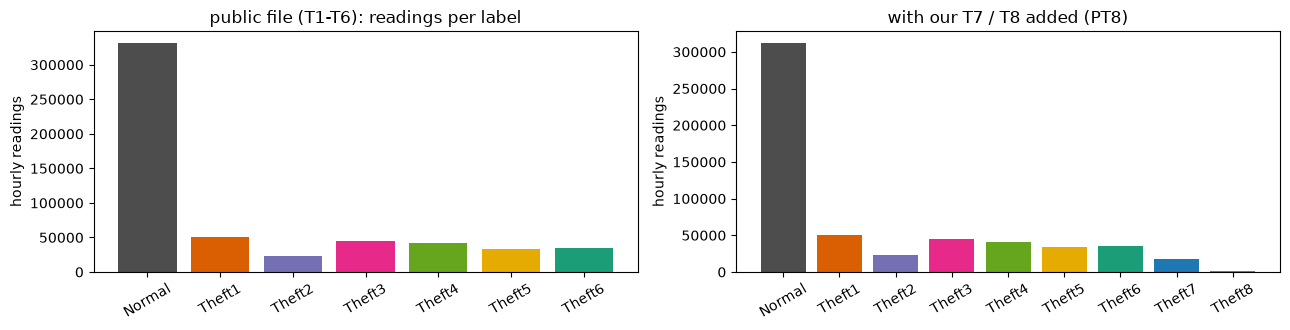

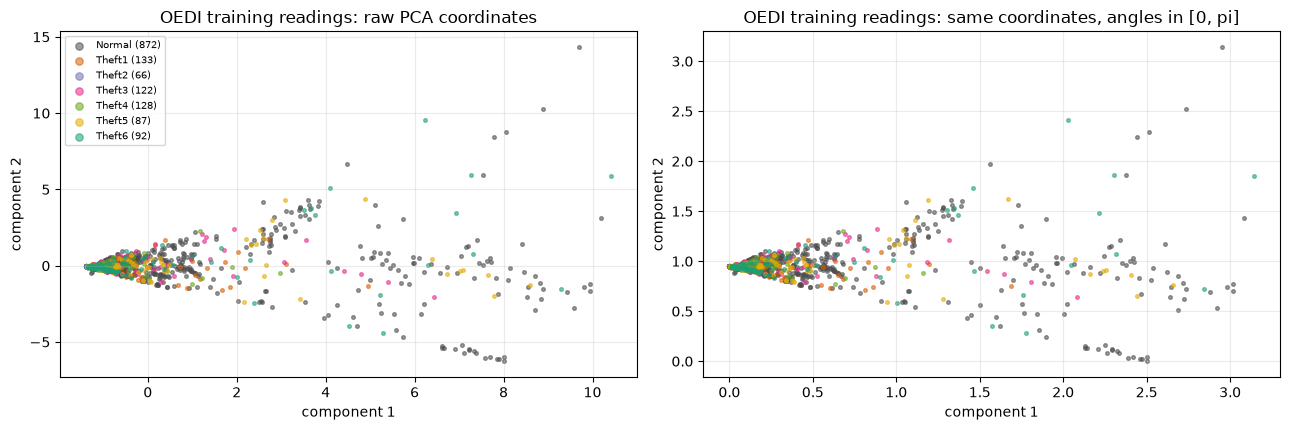

explained variance of the two components: 0.51, 0.15


In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
PAL = ["#4d4d4d", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#1b9e77", "#1f78b4", "#a6761d"]

def pca_panels(Xtr, labels, names, title, max_points=3000):
    # scatter of the first two principal components (fitted on Xtr) coloured by the ground-truth label, then the same
    # coordinates scaled to [0, pi] (the angle range of the embedding)
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr)
    Z = pca.transform(Xtr)
    ang = MinMaxScaler((0, np.pi)).fit(Z).transform(Z)
    sel = np.random.default_rng(SEED).choice(len(Z), min(max_points, len(Z)), replace=False)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
    for a, P, lab in [(ax[0], Z, "raw PCA coordinates"), (ax[1], ang, "same coordinates, angles in [0, pi]")]:
        for k, nme in enumerate(names):
            m = labels[sel] == k
            a.scatter(P[sel][m, 0], P[sel][m, 1], s=7, alpha=.55, color=PAL[k % len(PAL)], label=f"{nme} ({int((labels == k).sum())})")
        a.set_xlabel("component 1"); a.set_ylabel("component 2"); a.set_title(f"{title}: {lab}"); a.grid(alpha=.25)
    ax[0].legend(fontsize=7, markerscale=2, loc="best")
    plt.tight_layout(); plt.show()
    print("explained variance of the two components: %.2f, %.2f" % tuple(pca.explained_variance_ratio_))

print("=== Consumption domain: OEDI hourly load profiles with theft (Zidi et al. 2022) ===")
print("raw file shape:", raw.shape, "| clean table (15 corrupted rows dropped):", df[FEATS + ["Class", "theft"]].shape)
print("feature names (10 model inputs):", FEATS)
print("building types (Class, 16):", sorted(df.Class.unique()))
print("original label values of column 'theft' and their counts:")
print(df.theft.value_counts().sort_index().to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, d_, ttl in [(ax[0], df, "public file (T1-T6): readings per label"), (ax[1], df8, "with our T7 / T8 added (PT8)")]:
    vc = d_.theft.value_counts().sort_index()
    a.bar(vc.index, vc.values, color=[PAL[0]] + [PAL[i + 1] for i in range(len(vc) - 1)] if vc.index[0] == "Normal" else PAL[: len(vc)])
    a.set_title(ttl); a.set_ylabel("hourly readings"); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
# the training split of the first PT6 sample (same seed, size and split call as in section 5)
_rng = np.random.default_rng(BUDGET["SEEDS"][0]); _idx = _rng.choice(len(df), BUDGET["N_ROWS"], replace=False)
_tr, _ = train_test_split(_idx, test_size=VAL_FRAC + TEST_FRAC, random_state=BUDGET["SEEDS"][0], stratify=df.y.to_numpy()[_idx])
_sc = StandardScaler().fit(df[FEATS].to_numpy(float)[_tr])
_names = ["Normal"] + [f"Theft{i}" for i in range(1, 7)]
_lab = np.array([_names.index(t) for t in df.theft.to_numpy()[_tr]])
pca_panels(_sc.transform(df[FEATS].to_numpy(float)[_tr]), _lab, _names, "OEDI training readings")

=== Net-metering domain: Ausgrid solar homes + Open-Meteo weather + simulated attacks ===
net readings (customers, days, hours): (31, 1096, 24) | weather (days, hours): (1096, 24) | customers: 31
feature names: stage 1 = ['net_h0', 'net_h1', 'net_h2'] ... ['net_h21', 'net_h22', 'net_h23'] (24) | stage 2 adds irradiance_h*, temperature_h* (72) | stage 3 adds ['Cmax', 'day_of_week', 'season'] (75)
original labels (0 = honest day, 1-4 = attack family) and counts over the whole sample:
honest                    1000
attack 1 intermittent      249
attack 2 scaling           253
attack 3 time-varying      263
attack 4 history-based     235


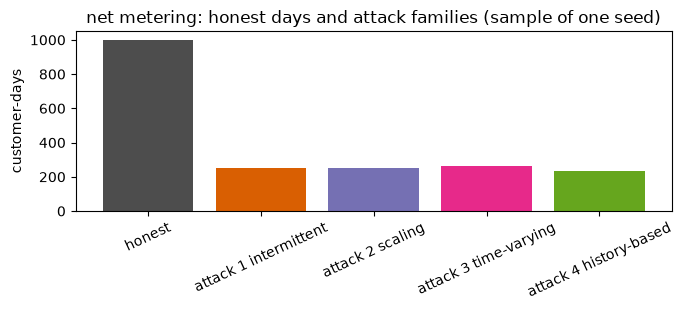

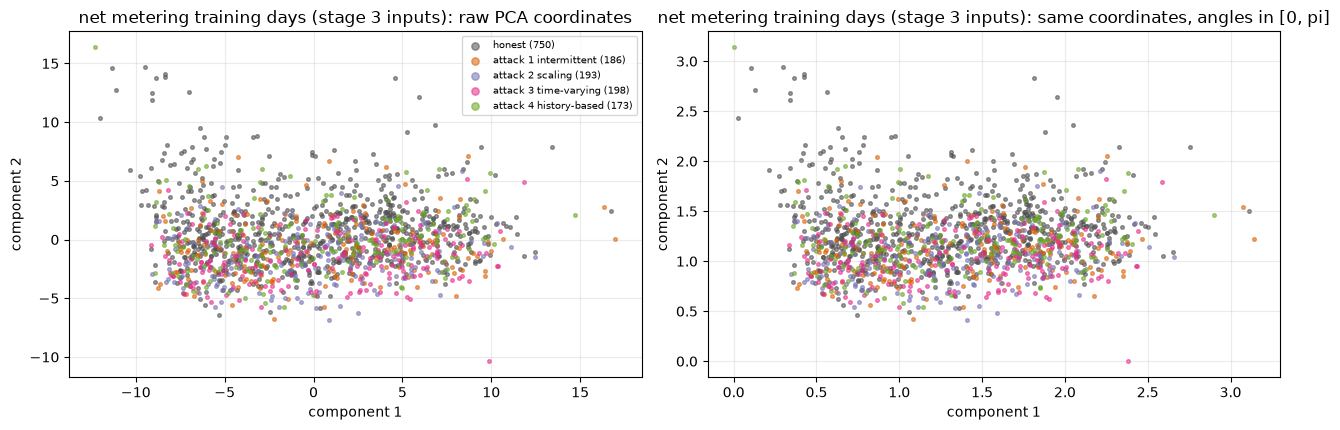

explained variance of the two components: 0.43, 0.13


In [23]:
print("=== Net-metering domain: Ausgrid solar homes + Open-Meteo weather + simulated attacks ===")
print("net readings (customers, days, hours):", NET.shape, "| weather (days, hours):", IRR.shape, "| customers:", len(CUST))
NM_FEATS = [f"net_h{h}" for h in range(24)] + [f"irradiance_h{h}" for h in range(24)] + [f"temperature_h{h}" for h in range(24)] + ["Cmax", "day_of_week", "season"]
print("feature names: stage 1 =", NM_FEATS[:24][:3], "...", NM_FEATS[21:24], "(24) | stage 2 adds irradiance_h*, temperature_h* (72) | stage 3 adds", NM_FEATS[72:], "(75)")
_nm = build_nm(BUDGET["NM_SEEDS"][0], BUDGET["N_DAYS"])
_names = ["honest", "attack 1 intermittent", "attack 2 scaling", "attack 3 time-varying", "attack 4 history-based"]
_k_all = np.concatenate([_nm[3]["ktr"], _nm[3]["kva"], _nm[3]["kte"]])
print("original labels (0 = honest day, 1-4 = attack family) and counts over the whole sample:")
print(pd.Series(_k_all).value_counts().sort_index().rename(dict(enumerate(_names))).to_string())
fig, ax = plt.subplots(figsize=(7, 3.2))
vc = pd.Series(_k_all).value_counts().sort_index()
ax.bar([_names[i] for i in vc.index], vc.values, color=[PAL[i] for i in vc.index]); ax.set_ylabel("customer-days"); ax.tick_params(axis="x", rotation=25)
ax.set_title("net metering: honest days and attack families (sample of one seed)"); plt.tight_layout(); plt.show()
pca_panels(_nm[3]["Xtr"], _nm[3]["ktr"], _names, "net metering training days (stage 3 inputs)")

## 10b. Training and testing on the net-metering data (Table 9)

In [24]:
t0 = time.time()
resnm, keepnm = run_nm(BUDGET["NM_SEEDS"], BUDGET["N_DAYS"], BUDGET["NM_EPOCHS"])
print("net-metering block done in %.0f s" % (time.time() - t0))

[net metering] seed 42 stage 1: inputs 24, train 1500, val 300, test 200


  stage 1 FH-QVC-DRC epoch   1/5  train loss 0.685  val loss 0.679  val acc 0.607  (8s)


  stage 1 FH-QVC-DRC epoch   2/5  train loss 0.652  val loss 0.646  val acc 0.647  (18s)


  stage 1 FH-QVC-DRC epoch   3/5  train loss 0.631  val loss 0.654  val acc 0.643  (31s)


  stage 1 FH-QVC-DRC epoch   4/5  train loss 0.632  val loss 0.613  val acc 0.680  (42s)


...

  stage 3 FH-QVC-DRC epoch   2/5  train loss 0.657  val loss 0.642  val acc 0.663  (14s)


  stage 3 FH-QVC-DRC epoch   3/5  train loss 0.649  val loss 0.629  val acc 0.680  (20s)


  stage 3 FH-QVC-DRC epoch   4/5  train loss 0.646  val loss 0.655  val acc 0.640  (26s)


  stage 3 FH-QVC-DRC epoch   5/5  train loss 0.656  val loss 0.629  val acc 0.687  (32s)


net-metering block done in 243 s


acc   prec   rec     f1    auc  train s
model                      stage                                           
FH-QVC-DRC (quantum)       1      0.650  0.692  0.54  0.607  0.678     53.8
                           2      0.500  0.500  1.00  0.667  0.500     61.2
                           3      0.705  0.681  0.77  0.723  0.712     31.5
Dense net (paper's 'LSTM') 1      0.625  0.676  0.48  0.561  0.732      9.0
                           2      0.635  0.645  0.60  0.622  0.725      5.6
                           3      0.700  0.700  0.70  0.700  0.716      3.1
RandomForest               1      0.725  0.732  0.71  0.721  0.838      2.0
                           2      0.715  0.701  0.75  0.725  0.826      2.9
                           3      0.735  0.724  0.76  0.741  0.828      2.2
SVC (rbf)                  1      0.670  0.689  0.62  0.653  0.741      0.2
                           2      0.720  0.716  0.73  0.723  0.781      0.3
                           3      0.715  0.705  0.74  0.722  0.781      0.2
XGBoost                    1      0.735  0.747  0.71  0.728  0.859      2.8
                           2      0.745  0.747  0.74  0.744  0.871     11.2
                           3      0.765  0.791  0.72  0.754  0.878      3.2
LightGBM                   1      0.770  0.807  0.71  0.755  0.873      2.9
                           2      0.780  0.798  0.75  0.773  0.873     46.8
                           3      0.775  0.796  0.74  0.767  0.890      2.1

attack 1 (intermittent): detected 18 of 23
attack 2 (scaling): detected 18 of 21
attack 3 (time-varying scaling): detected 25 of 28
attack 4 (history based): detected 16 of 28
false alarms on honest test days: 36 of 100


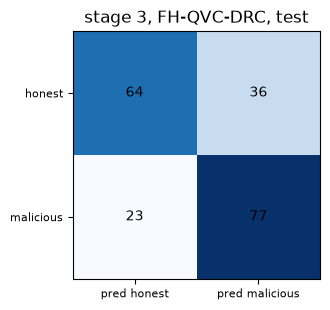

In [25]:
def nm_table(res):
    cols = ["acc", "prec", "rec", "f1", "auc"]
    g = res.groupby(["model", "stage"], sort=False)
    t = g[cols].mean().round(3)
    t["train s"] = g["train_time"].mean().round(1)
    return t
tab9 = nm_table(resnm)
order = ["FH-QVC-DRC (quantum)", "Dense net (paper's 'LSTM')"] + [m for m in tab9.index.get_level_values(0).unique() if m not in ("FH-QVC-DRC (quantum)", "Dense net (paper's 'LSTM')")]
tab9 = tab9.loc[order]
display(tab9)
# per attack type: recall of the quantum model on stage 3 (first seed)
d3 = keepnm[3]["data"]; pq = predict_net(keepnm[3]["models"]["FH-QVC-DRC (quantum)"][0], d3["Xte"])
for k, nme in [(1, "intermittent"), (2, "scaling"), (3, "time-varying scaling"), (4, "history based")]:
    mk = d3["kte"] == k
    print(f"attack {k} ({nme}): detected {int((pq[mk] >= .5).sum())} of {int(mk.sum())}")
print("false alarms on honest test days:", int(((pq >= .5) & (d3["kte"] == 0)).sum()), "of", int((d3["kte"] == 0).sum()))
cm = metrics(d3["yte"], pq)["cm"]
fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap="Blues"); ax.set_title("stage 3, FH-QVC-DRC, test")
for i in range(2):
    for j in range(2):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
ax.set_xticks([0, 1]); ax.set_xticklabels(["pred honest", "pred malicious"], fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(["honest", "malicious"], fontsize=8)
plt.tight_layout(); plt.show()

## 11. Paper Figures 2 and 3 with our own numbers: qubits and blocks

The paper varies the number of qubits (3 blocks) and the number of blocks (10 qubits) and finds a maximum around 10 qubits and 3 blocks.
We repeat both sweeps on **stage 3**, one seed, a short training budget (`SWEEP_EPOCHS`). With a single seed and a
few thousand test days the curves have a noise of roughly one accuracy point, so only large trends are meaningful.

  qubits =  4: acc 0.581  f1 0.604  auc 0.601  (8s, 1.9 s/epoch)


  qubits =  8: acc 0.625  f1 0.655  auc 0.681  (15s, 3.9 s/epoch)


  blocks =  1: acc 0.606  f1 0.648  auc 0.548  (7s, 1.9 s/epoch)


  blocks =  3: acc 0.588  f1 0.629  auc 0.590  (17s, 4.3 s/epoch)


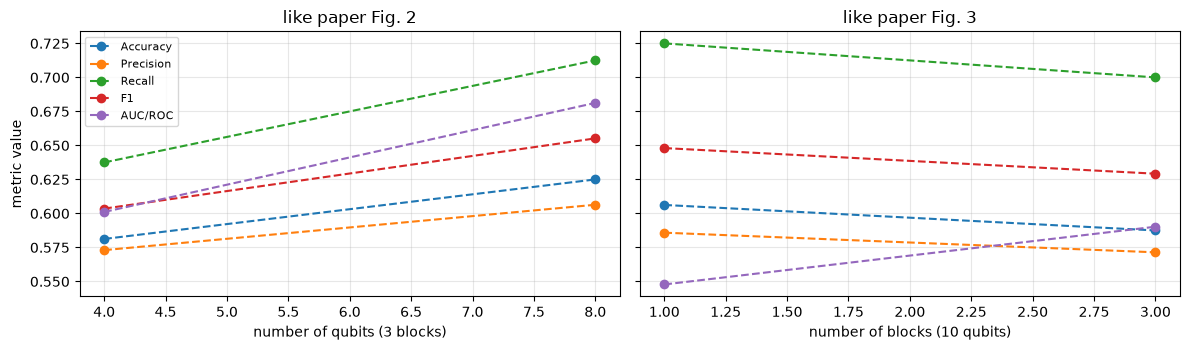

In [26]:
def sweep(kind, values, epochs, seed):
    d = build_nm(seed, BUDGET["SWEEP_DAYS"])[3]
    rows = []
    for v in values:
        nq, nb = (v, N_BLOCKS) if kind == "qubits" else (N_QUBITS, v)
        t0 = time.time()
        net, info = train_hybrid(d["Xtr"], d["ytr"], d["Xva"], d["yva"], SPEC_NM, True, epochs, seed, n_qubits=nq, n_blocks=nb, verbose=False)
        m = metrics(d["yte"], predict_net(net, d["Xte"])); m.update(value=v, sec_per_epoch=info["sec_per_epoch"]); rows.append(m)
        print(f"  {kind} = {v:2d}: acc {m['acc']:.3f}  f1 {m['f1']:.3f}  auc {m['auc']:.3f}  ({time.time()-t0:.0f}s, {info['sec_per_epoch']:.1f} s/epoch)")
    return pd.DataFrame(rows)

sweepq = sweepb = None
if BUDGET["RUN_SWEEPS"]:
    sweepq = sweep("qubits", BUDGET["SWEEP_QUBITS"], BUDGET["SWEEP_EPOCHS"], BUDGET["NM_SEEDS"][0])
    sweepb = sweep("blocks", BUDGET["SWEEP_BLOCKS"], BUDGET["SWEEP_EPOCHS"], BUDGET["NM_SEEDS"][0])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for a, sw, lab in [(ax[0], sweepq, "number of qubits (3 blocks)"), (ax[1], sweepb, "number of blocks (10 qubits)")]:
        for c, nme in [("acc", "Accuracy"), ("prec", "Precision"), ("rec", "Recall"), ("f1", "F1"), ("auc", "AUC/ROC")]:
            a.plot(sw.value, sw[c], "o--", label=nme)
        a.set_xlabel(lab); a.grid(alpha=.3)
    ax[0].set_ylabel("metric value"); ax[0].legend(fontsize=8); ax[0].set_title("like paper Fig. 2"); ax[1].set_title("like paper Fig. 3")
    plt.tight_layout(); plt.show()

## 12. Side by side with the paper

The paper's numbers below were read from its Tables 5-9 and Figures 2-3. A claim is **reproduced** when our value is within
0.02 of the paper's (accuracy points / F1), **not reached** when it is lower by more, **exceeded** when it is higher by more, and
**cannot be checked** when the quantity depends on something the notebook does not have (the authors' hardware, data generator, tuning).

In [27]:
# ---- the paper's numbers (Table 5, Table 6, Table 7, Table 9) ----
PAPER_T5 = {  # model: (ACC PT6, ACC PT8, F1 PT6, F1 PT8)
    "FH-QVC-DRC (quantum)": (0.87, 0.87, 0.86, 0.86), "Dense net (paper's 'LSTM')": (0.84, 0.81, 0.83, 0.78),
    "XGBoost": (0.85, 0.85, 0.82, 0.84), "LightGBM": (0.85, 0.85, 0.84, 0.85), "CatBoost": (0.86, 0.85, 0.83, 0.83)}
PAPER_T6 = dict(acc=[.86, .86, .86, .86, .86, .85, .85, .87, .87, .87, .88, .87, .88, .88, .87, .86],     # FH-QVC-DRC, PT6, 16 building types
                f1=[.85, .86, .84, .85, .84, .82, .84, .86, .85, .85, .86, .86, .86, .86, .86, .85])
PAPER_T7 = dict(acc=[.87, .87, .87, .84, .87, .84, .87, .89, .89, .84, .88, .85, .86, .89, .87, .85],     # FH-QVC-DRC, PT8
                f1=[.86, .87, .85, .84, .85, .83, .86, .86, .87, .83, .87, .85, .86, .88, .85, .86])
PAPER_T9 = {  # model: stage -> (acc, prec, rec, f1, auc)
    "FH-QVC-DRC (quantum)": {1: (.962, .988, .958, .973, .981), 2: (.963, .989, .960, .974, .982), 3: (.977, .991, .962, .976, .983)},
    "Dense net (paper's 'LSTM')": {1: (.928, .931, .928, .929, .938), 2: (.930, .935, .930, .932, .940), 3: (.948, .951, .948, .949, .946)},
    "CatBoost": {1: (.952, .956, .952, .954, .950), 2: (.956, .959, .956, .957, .952), 3: (.972, .972, .972, .972, .956)},
    "XGBoost": {1: (.958, .986, .960, .973, .954), 2: (.958, .987, .960, .973, .954), 3: (.973, .984, .972, .978, .960)},
    "LightGBM": {1: (.945, .985, .946, .965, .945), 2: (.946, .985, .947, .966, .946), 3: (.961, .983, .968, .975, .951)}}

Q = "FH-QVC-DRC (quantum)"
def verdict(paper, ours, tol=0.02):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"not reached (gap {gap:+.3f})" if gap < 0 else f"exceeded (gap {gap:+.3f})")

claims = []
def add(name, paper, ours, tol=0.02, note=""):
    claims.append(dict(claim=name, paper=paper, notebook=None if ours is None else round(float(ours), 3),
                       verdict=verdict(paper, ours, tol) if ours is not None else "cannot be checked", note=note))

def mean_of(res, model, col, **filt):
    r = res[res.model == model]
    for k, v in filt.items():
        r = r[r[k] == v]
    return float(r[col].mean()) if len(r) else None

# Table 5, consumption domain
add("Table 5: FH-QVC-DRC accuracy, PT6", 0.87, mean_of(res6, Q, "acc"))
add("Table 5: FH-QVC-DRC F1, PT6", 0.86, mean_of(res6, Q, "f1"))
add("Table 5: FH-QVC-DRC accuracy, PT8", 0.87, mean_of(res8, Q, "acc"), note="our T7/T8, not the authors' generator")
add("Table 5: FH-QVC-DRC F1, PT8", 0.86, mean_of(res8, Q, "f1"), note="our T7/T8, not the authors' generator")
add("Table 5 (large held-out pool): accuracy, PT6", 0.87, mean_of(res6, Q, "acc_pool"), note="same models, thousands of unseen readings, less noisy than the 10 % split")
add("Table 5 (large held-out pool): accuracy, PT8", 0.87, mean_of(res8, Q, "acc_pool"), note="same models, thousands of unseen readings; our T7/T8")
for res, tag in [(res6, "PT6"), (res8, "PT8")]:
    best = res[res.model != Q].groupby("model").acc.mean().sort_values()
    gap = mean_of(res, Q, "acc") - best.iloc[-1]
    claims.append(dict(claim=f"Table 5: QML beats every classical model in accuracy, {tag}", paper="yes (+0.01 to +0.06)", notebook=round(gap, 3),
                       verdict="reproduced" if gap > 0 else f"not reached (best classical {best.index[-1]} by {-gap:.3f})", note="notebook value = quantum minus best classical accuracy"))
# Tables 6 and 7, per building type
for tab, pap, tag in [(tab6, PAPER_T6, "Table 6 (PT6)"), (tab7, PAPER_T7, "Table 7 (PT8)")]:
    for k, nme in [("ACC", "acc"), ("F1", "f1")]:
        ours = float(tab.loc[tab.index != "MEAN", (Q, k)].mean())
        add(f"{tag}: mean per-building-type {k}", round(float(np.mean(pap[nme])), 3), ours)
# Table 9, net metering
for s in (1, 2, 3):
    for i, m in enumerate(["accuracy", "precision", "recall", "F1", "AUC"]):
        col = ["acc", "prec", "rec", "f1", "auc"][i]
        add(f"Table 9: stage {s} {m}", PAPER_T9[Q][s][i], mean_of(resnm, Q, col, stage=s))
for s in (1, 2, 3):
    best = resnm[(resnm.model != Q) & (resnm.stage == s)].groupby("model").auc.mean().sort_values()
    gap = mean_of(resnm, Q, "auc", stage=s) - best.iloc[-1]
    claims.append(dict(claim=f"Table 9: QML has the best AUC, stage {s}", paper="yes (+0.02 to +0.03)", notebook=round(gap, 3),
                       verdict="reproduced" if gap > 0 else f"not reached (best classical {best.index[-1]} by {-gap:.3f})", note="notebook value = quantum minus best classical AUC"))
a1, a3 = mean_of(resnm, Q, "acc", stage=1), mean_of(resnm, Q, "acc", stage=3)
claims.append(dict(claim="Table 9: stage 3 better than stage 1 (accuracy)", paper="+0.015", notebook=round(a3 - a1, 3),
                   verdict="reproduced" if a3 - a1 >= 0.005 else "not reached", note="more inputs help"))
# Figures 2 and 3
for sw, nme, target in [(sweepq, "qubits", 10), (sweepb, "blocks", 3)]:
    if sw is None or target not in list(sw.value):
        claims.append(dict(claim=f"Fig. {2 if nme == 'qubits' else 3}: accuracy peaks at {target} {nme}", paper=f"peak at {target}", notebook=None, verdict="cannot be checked", note=f"{target} not in the sweep of this run"))
    else:
        best = sw.loc[sw.acc.idxmax()]
        ok = float(sw[sw.value == target].acc.iloc[0]) >= best.acc - 0.01
        claims.append(dict(claim=f"Fig. {2 if nme == 'qubits' else 3}: accuracy peaks at {target} {nme}", paper=f"peak at {target}", notebook=int(best.value),
                           verdict="reproduced" if ok else "not reached", note=f"best of the sweep at {int(best.value)} {nme}; within 0.01 of the best counts"))
# Table 10
spe = keep6["models"][Q][2]["sec_per_epoch"]
claims.append(dict(claim="Table 10: ~50 s per epoch (3 blocks, 10 qubits)", paper="~50 s", notebook=round(spe, 1), verdict="cannot be checked",
                   note="different CPU, data size and simulator; our fast simulator makes epochs of a few thousand samples cost seconds"))
claims_df = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80, "display.width", 250)
display(claims_df)
print(claims_df.verdict.str.split(" ").str[0].value_counts().to_string())

,claim,paper,notebook,verdict,note
0,"Table 5: FH-QVC-DRC accuracy, PT6",0.87,0.535,not reached (gap -0.335),
1,"Table 5: FH-QVC-DRC F1, PT6",0.86,0.456,not reached (gap -0.404),
2,"Table 5: FH-QVC-DRC accuracy, PT8",0.87,0.645,not reached (gap -0.225),"our T7/T8, not the authors' generator"
3,"Table 5: FH-QVC-DRC F1, PT8",0.86,0.594,not reached (gap -0.266),"our T7/T8, not the authors' generator"
4,"Table 5 (large held-out pool): accuracy, PT6",0.87,0.629,not reached (gap -0.241),"same models, thousands of unseen readings, less noisy than the 10 % split"
5,"Table 5 (large held-out pool): accuracy, PT8",0.87,0.626,not reached (gap -0.244),"same models, thousands of unseen readings; our T7/T8"
6,"Table 5: QML beats every classical model in accuracy, PT6",yes (+0.01 to +0.06),-0.360,not reached (best classical XGBoost by 0.360),notebook value = quantum minus best classical accuracy
7,"Table 5: QML beats every classical model in accuracy, PT8",yes (+0.01 to +0.06),-0.265,not reached (best classical XGBoost by 0.265),notebook value = quantum minus best classical accuracy
8,Table 6 (PT6): mean per-building-type ACC,0.866,0.632,not reached (gap -0.234),
9,Table 6 (PT6): mean per-building-type F1,0.851,0.532,not reached (gap -0.319),


verdict
not           30
cannot         2
exceeded       1
reproduced     1


In [28]:
# The paper's Table 5 next to our numbers for every model (same inputs for all of them)
rows = []
for model, (a6, a8, f6, f8) in PAPER_T5.items():
    rows.append(dict(model=model, paper_ACC_PT6=a6, ours_ACC_PT6=mean_of(res6, model, "acc"), ours_ACC_PT6_pool=mean_of(res6, model, "acc_pool"),
                     paper_ACC_PT8=a8, ours_ACC_PT8=mean_of(res8, model, "acc"), ours_ACC_PT8_pool=mean_of(res8, model, "acc_pool"),
                     paper_F1_PT6=f6, ours_F1_PT6=mean_of(res6, model, "f1"), paper_F1_PT8=f8, ours_F1_PT8=mean_of(res8, model, "f1")))
for model in ["RandomForest", "SVC (rbf)"]:
    rows.append(dict(model=model + " (not in paper)", ours_ACC_PT6=mean_of(res6, model, "acc"), ours_ACC_PT6_pool=mean_of(res6, model, "acc_pool"),
                     ours_ACC_PT8=mean_of(res8, model, "acc"), ours_ACC_PT8_pool=mean_of(res8, model, "acc_pool"),
                     ours_F1_PT6=mean_of(res6, model, "f1"), ours_F1_PT8=mean_of(res8, model, "f1")))
display(pd.DataFrame(rows).set_index("model").round(3))
print("Leak check (whole building series held out), PT6 accuracy:")
display(resg.set_index("model")[["acc", "f1", "auc"]].round(3))

,paper_ACC_PT6,ours_ACC_PT6,ours_ACC_PT6_pool,paper_ACC_PT8,ours_ACC_PT8,ours_ACC_PT8_pool,paper_F1_PT6,ours_F1_PT6,paper_F1_PT8,ours_F1_PT8
model,,,,,,,,,,
FH-QVC-DRC (quantum),0.87,0.535,0.629,0.87,0.645,0.626,0.86,0.456,0.86,0.594
Dense net (paper's 'LSTM'),0.84,0.515,0.616,0.81,0.645,0.618,0.83,0.481,0.78,0.628
XGBoost,0.85,0.895,0.891,0.85,0.910,0.899,0.82,0.873,0.84,0.894
LightGBM,0.85,0.880,0.890,0.85,0.910,0.894,0.84,0.852,0.85,0.899
CatBoost,0.86,NaN,NaN,0.85,NaN,NaN,0.83,NaN,0.83,NaN
RandomForest (not in paper),NaN,0.885,0.886,NaN,0.910,0.884,NaN,0.857,NaN,0.897
SVC (rbf) (not in paper),NaN,0.575,0.643,NaN,0.650,0.630,NaN,0.514,NaN,0.643


Leak check (whole building series held out), PT6 accuracy:


,acc,f1,auc
model,,,
FH-QVC-DRC (quantum),0.656,0.294,0.686
Dense net (paper's 'LSTM'),0.648,0.435,0.681
RandomForest,0.882,0.844,0.922
SVC (rbf),0.600,0.071,0.721
XGBoost,0.897,0.870,0.931
LightGBM,0.898,0.871,0.930


## 13. Reading the paper critically

*What the numbers above can support, and what they cannot.* (The text below is written for the results of a full run. In
`FAST_MODE` the quantum model is trained for a handful of epochs only, so it is expected to fall far below the paper's numbers;
the comments about the *data* and the *protocol* hold in both modes.)

1. **The consumption task is easy for the right classical model, and the paper's baselines are weak.** The label sits on single
   hourly readings and thefts break simple physical relations between the ten channels (zeros, repeated daily means, rescaled
   channels). Gradient-boosted trees recover these relations from a few thousand readings. In the paper XGBoost, LightGBM and CatBoost score
   0.85-0.86 accuracy; with the same inputs and default settings they score clearly higher here (see the table in section 12).
   The paper's "better than all classical competitors" therefore depends on how much effort went into the baselines.
2. **"LSTM" is not an LSTM.** Table 4 describes a dense stack. There is no temporal model, although the data are time series.
   A sequence model that sees a whole day would be the natural classical competitor.
3. **Random splits of neighbouring hours.** Readings of the same day have the same label and are similar. Splitting at random
   puts siblings in train and test, which can flatter a model. The grouped-split check in section 8 (whole building series held out)
   shows that the tree models move by about a point only, so leakage between neighbouring hours is not what makes the classical baselines strong here.
4. **Synthetic attacks, authors' parameters.** In both domains the malicious samples are *simulated* by formulas (Table 2, Table 3) and honest
   customers are assumed to be honest. A detector that recognises the formulas has not shown that it detects real fraud. The parameter ranges of the
   attacks and the class balance of the net-metering set are not given in the paper; this notebook had to choose them, and
   accuracy near 0.96-0.98 depends strongly on these choices (for instance, an attack that rescales a reading by 0.9 is
   far harder than one that rescales by 0.1).
5. **Small test sets.** With about 10 % of a few thousand samples for testing, one accuracy point is 20-30 test samples. The paper reports no
   confidence intervals and "average outcome scores over the simulations" without the number of runs. Differences of 0.01 in Table 5 are within noise.
6. **No evidence of a quantum advantage.** All results are exact noiseless simulations, so the quantum layer is just a particular
   differentiable function with about 90 parameters sandwiched between classical layers. A classical dense network of the same width is the
   fair control; the paper's own control ("LSTM") is trained for the same number of epochs but, as the paper notes, keeps improving up to
   3500 epochs, so the comparison at 250 epochs favours the model that converges faster per epoch, not necessarily the better model. Also, the
   quantum layer is slower: in our runs the hybrid network needs about ten times the training time of the dense network of the same width, and
   far more than a gradient-boosting model (Table 10 of the paper reports the same ordering for the authors' simulator).
7. **Hyper-parameter selection.** Qubits, blocks and epochs were tuned on AUC/ROC curves that look like validation curves (Figs. 2-3), but the paper does not say whether
   the test split was used for that selection.
8. **Reproducibility.** The linked code repository contains different notebooks and a different data file than the two datasets of the paper; the
   attack generator is not published. This notebook reconstructs the pipeline from the text and the public datasets.

## 14. Exercises

1. **Better classical baselines.** Replace the baselines by a 1-D CNN or GRU that receives a whole 24-hour day of the consumption data (reshape the file by day). Does the
   quantum model still beat it?
2. **Optimiser and epochs.** Switch the optimiser to `torch.optim.SGD(lr=0.05, momentum=0.9)` (the paper's choice) and train 250 epochs on `N_ROWS = 2000`. How much of the gap to the paper is training budget?
3. **Entangling layers.** Set `N_LAYERS = 2` or `3` and rerun the qubit sweep. Does the trainable-parameter count explain the curves of Figs. 2-3?
4. **Harder attacks.** Change the attack ranges in section 10 (e.g. `a ~ U(0.7, 0.95)`, `M1 ~ U(0.95, 1)`). How quickly does the accuracy of every model fall, and does the ranking change?
5. **Noise.** Replace the fast simulator by `qml.device("default.mixed")` with `qml.DepolarizingChannel(0.01)` after every layer (4 qubits, one block, a few hundred samples) and measure the loss of accuracy; this is the paper's own "future work".